# Parity-controlled electron-hole interference in Fröhlich exciton-phonon coupling

Companion notebook for M. O. Atambo, *Parity-controlled electron-hole interference in Fröhlich exciton-phonon coupling: exact results for the hydrogenic model*.

This notebook reproduces, from scratch and in order:

| Output | Manuscript item |
|---|---|
| Table of small-$q$ coefficients | Table I |
| `figure1_form_factors.pdf` | Fig. 1 |
| Table of $|\mathcal F|^2$ at $q a_X = 0.5$ | Table II |
| `figure2_parity_selection_rule.pdf` | Fig. 2 |
| Table of integrated dressing at $\Lambda = 15.8$ | Table III |
| `figure3_phase_diagram.pdf` | Fig. 3 |

The Huang-Rhys ratio $R(\eta)$ and the recoil linewidths are in the companion record (Zenodo DOI 10.5281/zenodo.23377376).

**Conventions.** Lengths in units of the exciton Bohr radius ($a_X = 1$). Mass fractions $\alpha_e = m_e/M$, $\alpha_h = m_h/M$; mass asymmetry $\eta = (m_h - m_e)/(m_h + m_e)$, so $\alpha_{h,e} = (1\pm\eta)/2$. Form factor $\mathcal F_{n'n}(q) = \langle n'| e^{-i\alpha_e \mathbf q\cdot\mathbf r} - e^{i\alpha_h \mathbf q\cdot\mathbf r}|n\rangle$.

**Run:** *Kernel → Restart & Run All*. Runtime is a few minutes on a laptop (the phase diagram is the slow step). Tables are also written to CSV files.

In [1]:
import sys, platform
import numpy as np, scipy, matplotlib
import scipy.integrate as integrate
print("Python", platform.python_version(), "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

Python 3.10.12 | numpy 2.2.6 | scipy 1.15.3 | matplotlib 3.10.6


## Plot style

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# MATPLOTLIT CONFIGURATION
# ============================================================
# Column widths in inches (high standard)
COL_WIDTH_SINGLE = 3.5   # 8.6 cm
COL_WIDTH_DOUBLE = 7.0   # 17.2 cm

# Font sizes (in points)
FONT_SIZE_LABEL  = 10    # Axis labels
FONT_SIZE_TICK   = 9     # Tick labels
FONT_SIZE_TITLE  = 11    # Panel titles
FONT_SIZE_LEGEND = 9     # Legend text
FONT_SIZE_ANNO   = 9     # Annotations

# Line widths (in points)
LINE_WIDTH_MAIN  = 2.0   # Main curves
LINE_WIDTH_REF   = 1.0   # Reference/asymptotic lines
LINE_WIDTH_AXIS  = 1.0   # Axis spines

# DPI for raster elements (set high for safety)
DPI = 600

# Configure matplotlib
mpl.rcParams.update({
    # Font
    'font.family':        'sans-serif',
    'font.sans-serif':    ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size':          FONT_SIZE_TICK,
    'mathtext.fontset':   'dejavusans',  # Use DejaVu for math
    
    # Figure
    'figure.dpi':         DPI,
    'savefig.dpi':        DPI,
    'figure.facecolor':   'white',
    'figure.edgecolor':   'white',
    'figure.autolayout':  False,
    
    # Axes
    'axes.linewidth':     LINE_WIDTH_AXIS,
    'axes.labelsize':     FONT_SIZE_LABEL,
    'axes.titlesize':     FONT_SIZE_TITLE,
    'axes.titleweight':   'bold',
    'axes.prop_cycle':    mpl.cycler('color', 
                            ['#1f77b4', '#d62728', '#2ca02c', 
                             '#ff7f0e', '#9467bd', '#8c564b']),
    
    # Ticks
    'xtick.labelsize':    FONT_SIZE_TICK,
    'ytick.labelsize':    FONT_SIZE_TICK,
    'xtick.major.width':  LINE_WIDTH_AXIS,
    'ytick.major.width':  LINE_WIDTH_AXIS,
    'xtick.major.size':   4,
    'ytick.major.size':   4,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.top':          True,
    'ytick.right':        True,
    
    # Lines
    'lines.linewidth':    LINE_WIDTH_MAIN,
    'lines.markersize':   5,
    
    # Legend
    'legend.fontsize':    FONT_SIZE_LEGEND,
    'legend.frameon':     False,
    'legend.handlelength': 2.0,
    
    # Grid (off by default, add manually if needed)
    'axes.grid':          False,
    
    # Saving
    'savefig.bbox':       'tight',
    'savefig.pad_inches': 0.05,
})

def highquality_figure(width='single', height_ratio=0.75, nrows=1, ncols=1, **kwargs):
    """
    Create a  good-sized figure.
    
    Parameters
    ----------
    width : str
        'single' (3.5 in) or 'double' (7.0 in)
    height_ratio : float
        height = width * height_ratio
    nrows, ncols : int
        Subplot grid
    """
    w = COL_WIDTH_SINGLE if width == 'single' else COL_WIDTH_DOUBLE
    h = w * height_ratio
    fig, axes = plt.subplots(nrows, ncols, figsize=(w, h), **kwargs)
    return fig, axes

def highquality_save(fig, filename, transparent=False):
    """Save figure at high resolution."""
    fig.savefig(filename, dpi=DPI, transparent=transparent, 
                bbox_inches='tight', pad_inches=0.02)
    print(f"Saved: {filename} ({fig.get_size_inches()[0]:.1f}\" x {fig.get_size_inches()[1]:.1f}\")")

## Hydrogenic matrix elements and exciton form factors

$g(k) = \langle 1s|e^{ikz}|1s\rangle$ (real, even) and $\langle 2p_z|e^{ikz}|1s\rangle = iA(k)$ ($A$ real, odd). Then
$\mathcal F_{1s,1s} = g(\alpha_e q) - g(\alpha_h q)$ and $|\mathcal F_{1s,2p}| = |A(\alpha_e q) + A(\alpha_h q)|$.

In [3]:
def R_1s(r, a=1.0): return 2 * a**(-1.5) * np.exp(-r/a)
def R_2p(r, a=1.0): return (1/(2*np.sqrt(6))) * a**(-1.5) * (r/a) * np.exp(-r/(2*a))

def j0(x): return 1.0 if x == 0 else np.sin(x)/x
def j1(x): return 0.0 if x == 0 else np.sin(x)/x**2 - np.cos(x)/x

def calc_G_ss(k, a=1.0):
    "g(k) = <1s|exp(ikz)|1s>"
    res, _ = integrate.quad(lambda r: R_1s(r, a)**2 * j0(k*r) * r**2, 0, np.inf, limit=200)
    return res

def calc_A_sp(k, a=1.0):
    "A(k), with <2p_z|exp(ikz)|1s> = i A(k)"
    res, _ = integrate.quad(lambda r: R_2p(r, a) * R_1s(r, a) * j1(k*r) * r**2, 0, np.inf, limit=200)
    return res * np.sqrt(3)

def F_1s_1s(q, alpha_e, alpha_h):
    return calc_G_ss(alpha_e*q) - calc_G_ss(alpha_h*q)

def F_1s_2p(q, alpha_e, alpha_h):
    return calc_A_sp(alpha_h*q) + calc_A_sp(alpha_e*q)

def alphas(eta):
    return (1 - eta)/2, (1 + eta)/2   # (alpha_e, alpha_h)

# Checks: closed form g(k) = (1 + k^2/4)^-2, and exact zero at eta = 0
for k in [0.3, 1.0, 3.0]:
    assert abs(calc_G_ss(k) - (1 + k**2/4)**-2) < 1e-10
assert abs(F_1s_1s(0.5, *alphas(0.0))) < 1e-14
DIPOLE = 2**7*np.sqrt(2)/3**5          # <2p_z|z|1s> in units of a_X
print("closed-form check passed; <2p_z|z|1s> =", DIPOLE)

closed-form check passed; <2p_z|z|1s> = 0.7449355390278032


## Table I: leading small-$q$ coefficients ($\eta = 0.6$)

In [4]:
eta = 0.6; ae, ah = alphas(eta); q0 = 1e-3
c_ss = F_1s_1s(q0, ae, ah) / q0**2
c_sp = F_1s_2p(q0, ae, ah) / q0
print(f"1s->1s  order q^2 : numerical {c_ss:.6f}   analytical eta/2 = {eta/2:.6f}")
print(f"1s->2p  order q^1 : numerical {abs(c_sp):.6f}   analytical 2^7 sqrt2/3^5 = {DIPOLE:.6f}")
np.savetxt("table1_coefficients.csv",
           [[2, c_ss, eta/2], [1, abs(c_sp), DIPOLE]], delimiter=",",
           header="order,numerical,analytical (rows: 1s->1s, 1s->2p)", comments="")

1s->1s  order q^2 : numerical 0.300000   analytical eta/2 = 0.300000
1s->2p  order q^1 : numerical 0.744935   analytical 2^7 sqrt2/3^5 = 0.744936


## Figure 1: form factors at $\eta = 0.6$

Asymptotes: $|\mathcal F_{1s,1s}|^2 \to (\eta/2)^2 q^4$ and $|\mathcal F_{1s,2p}|^2 \to \langle 2p_z|z|1s\rangle^2 q^2$ (the electron and hole dipole terms add, $\alpha_e + \alpha_h = 1$).

Saved: figure1_form_factors.pdf (3.5" x 2.6")
Saved: figure1_form_factors.png (3.5" x 2.6")


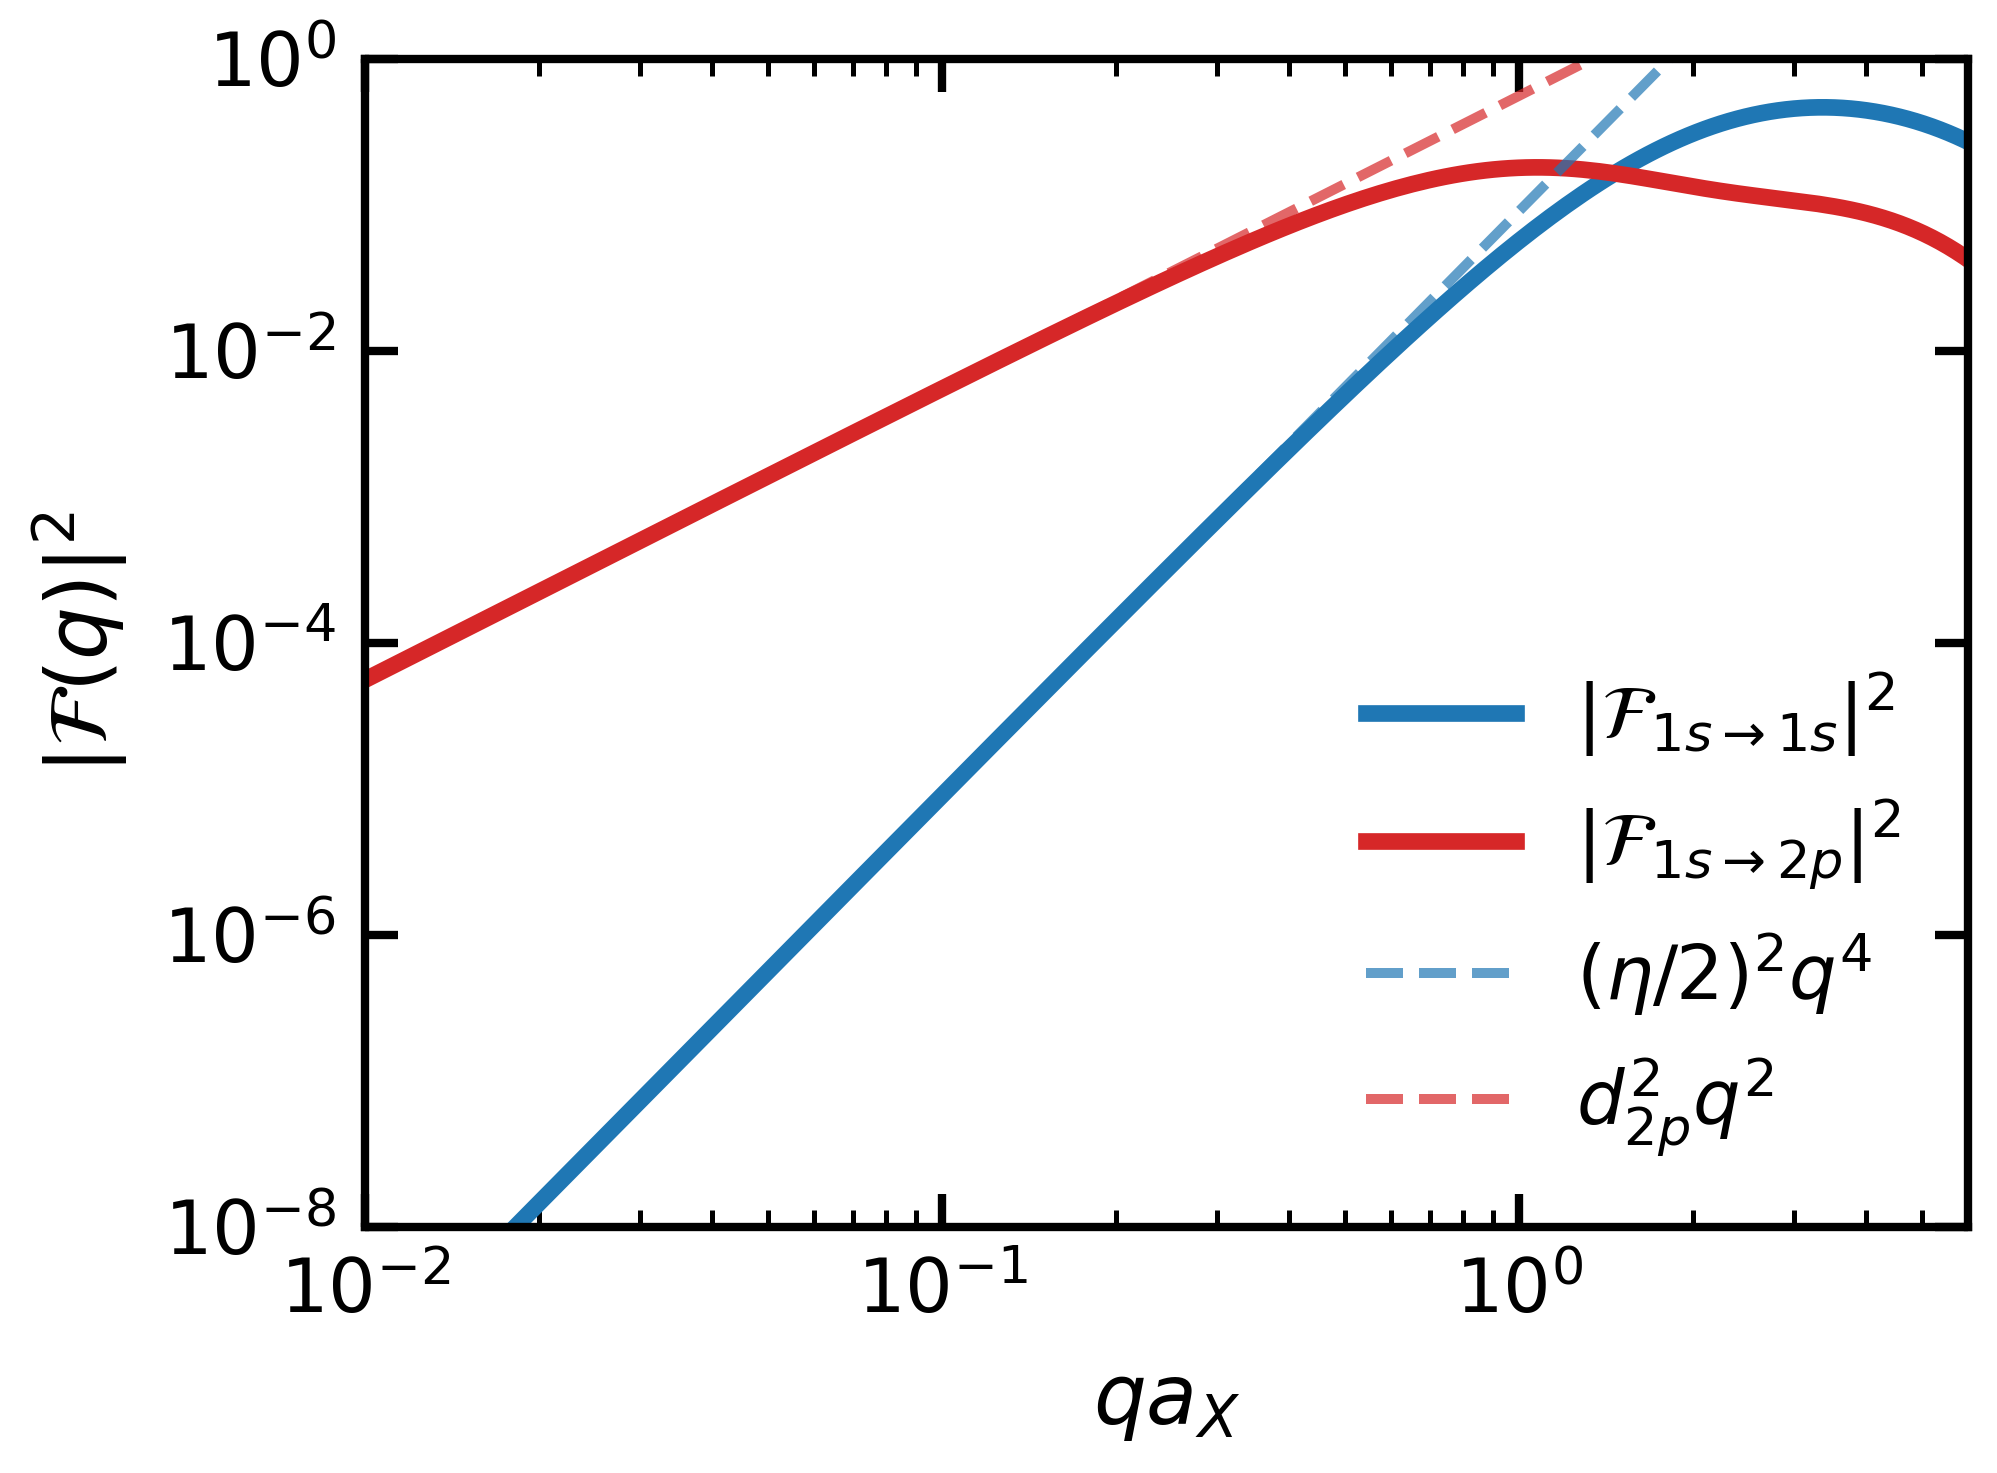

In [5]:
from matplotlib.ticker import LogLocator
q_vals = np.logspace(-2, 0.8, 200)
F_ss = np.array([F_1s_1s(q, ae, ah)**2 for q in q_vals])
F_sp = np.array([F_1s_2p(q, ae, ah)**2 for q in q_vals])
asymp_ss = (eta/2)**2 * q_vals**4
asymp_sp = DIPOLE**2 * q_vals**2

fig, ax = highquality_figure(width='single')
ax.plot(q_vals, F_ss, color='#1f77b4', label=r'$|\mathcal{F}_{1s\to1s}|^2$')
ax.plot(q_vals, F_sp, color='#d62728', label=r'$|\mathcal{F}_{1s\to2p}|^2$')
ax.plot(q_vals, asymp_ss, color='#1f77b4', lw=1.2, ls='--', alpha=0.7, label=r'$(\eta/2)^2 q^4$')
ax.plot(q_vals, asymp_sp, color='#d62728', lw=1.2, ls='--', alpha=0.7, label=r'$d_{2p}^2 q^2$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.xaxis.set_minor_locator(LogLocator(subs='auto')); ax.yaxis.set_minor_locator(LogLocator(subs='auto'))
ax.set_xlabel(r'$q a_X$'); ax.set_ylabel(r'$|\mathcal{F}(q)|^2$')
ax.set_xlim(0.01, 6.0); ax.set_ylim(1e-8, 1e0)
ax.legend(loc='lower right')
plt.tight_layout()
highquality_save(fig, 'figure1_form_factors.pdf'); highquality_save(fig, 'figure1_form_factors.png')
plt.show()

## Table II: $|\mathcal F|^2$ at fixed $q a_X = 0.5$

In [6]:
rows = []
print(f"{'eta':>5} {'alpha_e':>8} {'alpha_h':>8} {'|F_ss|^2':>10} {'|F_sp|^2':>10}")
for eta_i in [0.0, 0.2, 0.4, 0.6, 0.8]:
    e_, h_ = alphas(eta_i)
    fss, fsp = F_1s_1s(0.5, e_, h_)**2, F_1s_2p(0.5, e_, h_)**2
    rows.append([eta_i, e_, h_, fss, fsp])
    print(f"{eta_i:5.2f} {e_:8.3f} {h_:8.3f} {fss:10.6f} {fsp:10.6f}")
np.savetxt("table2_fixed_q.csv", rows, delimiter=",",
           header="eta,alpha_e,alpha_h,Fss2,Fsp2", comments="")

  eta  alpha_e  alpha_h   |F_ss|^2   |F_sp|^2
 0.00    0.500    0.500   0.000000   0.117702
 0.20    0.400    0.600   0.000567   0.115593
 0.40    0.300    0.700   0.002246   0.109458
 0.60    0.200    0.800   0.004965   0.099849
 0.80    0.100    0.900   0.008612   0.087601


## Figure 2: parity selection rule

Saved: figure2_parity_selection_rule.pdf (7.0" x 3.1")
Saved: figure2_parity_selection_rule.png (7.0" x 3.1")


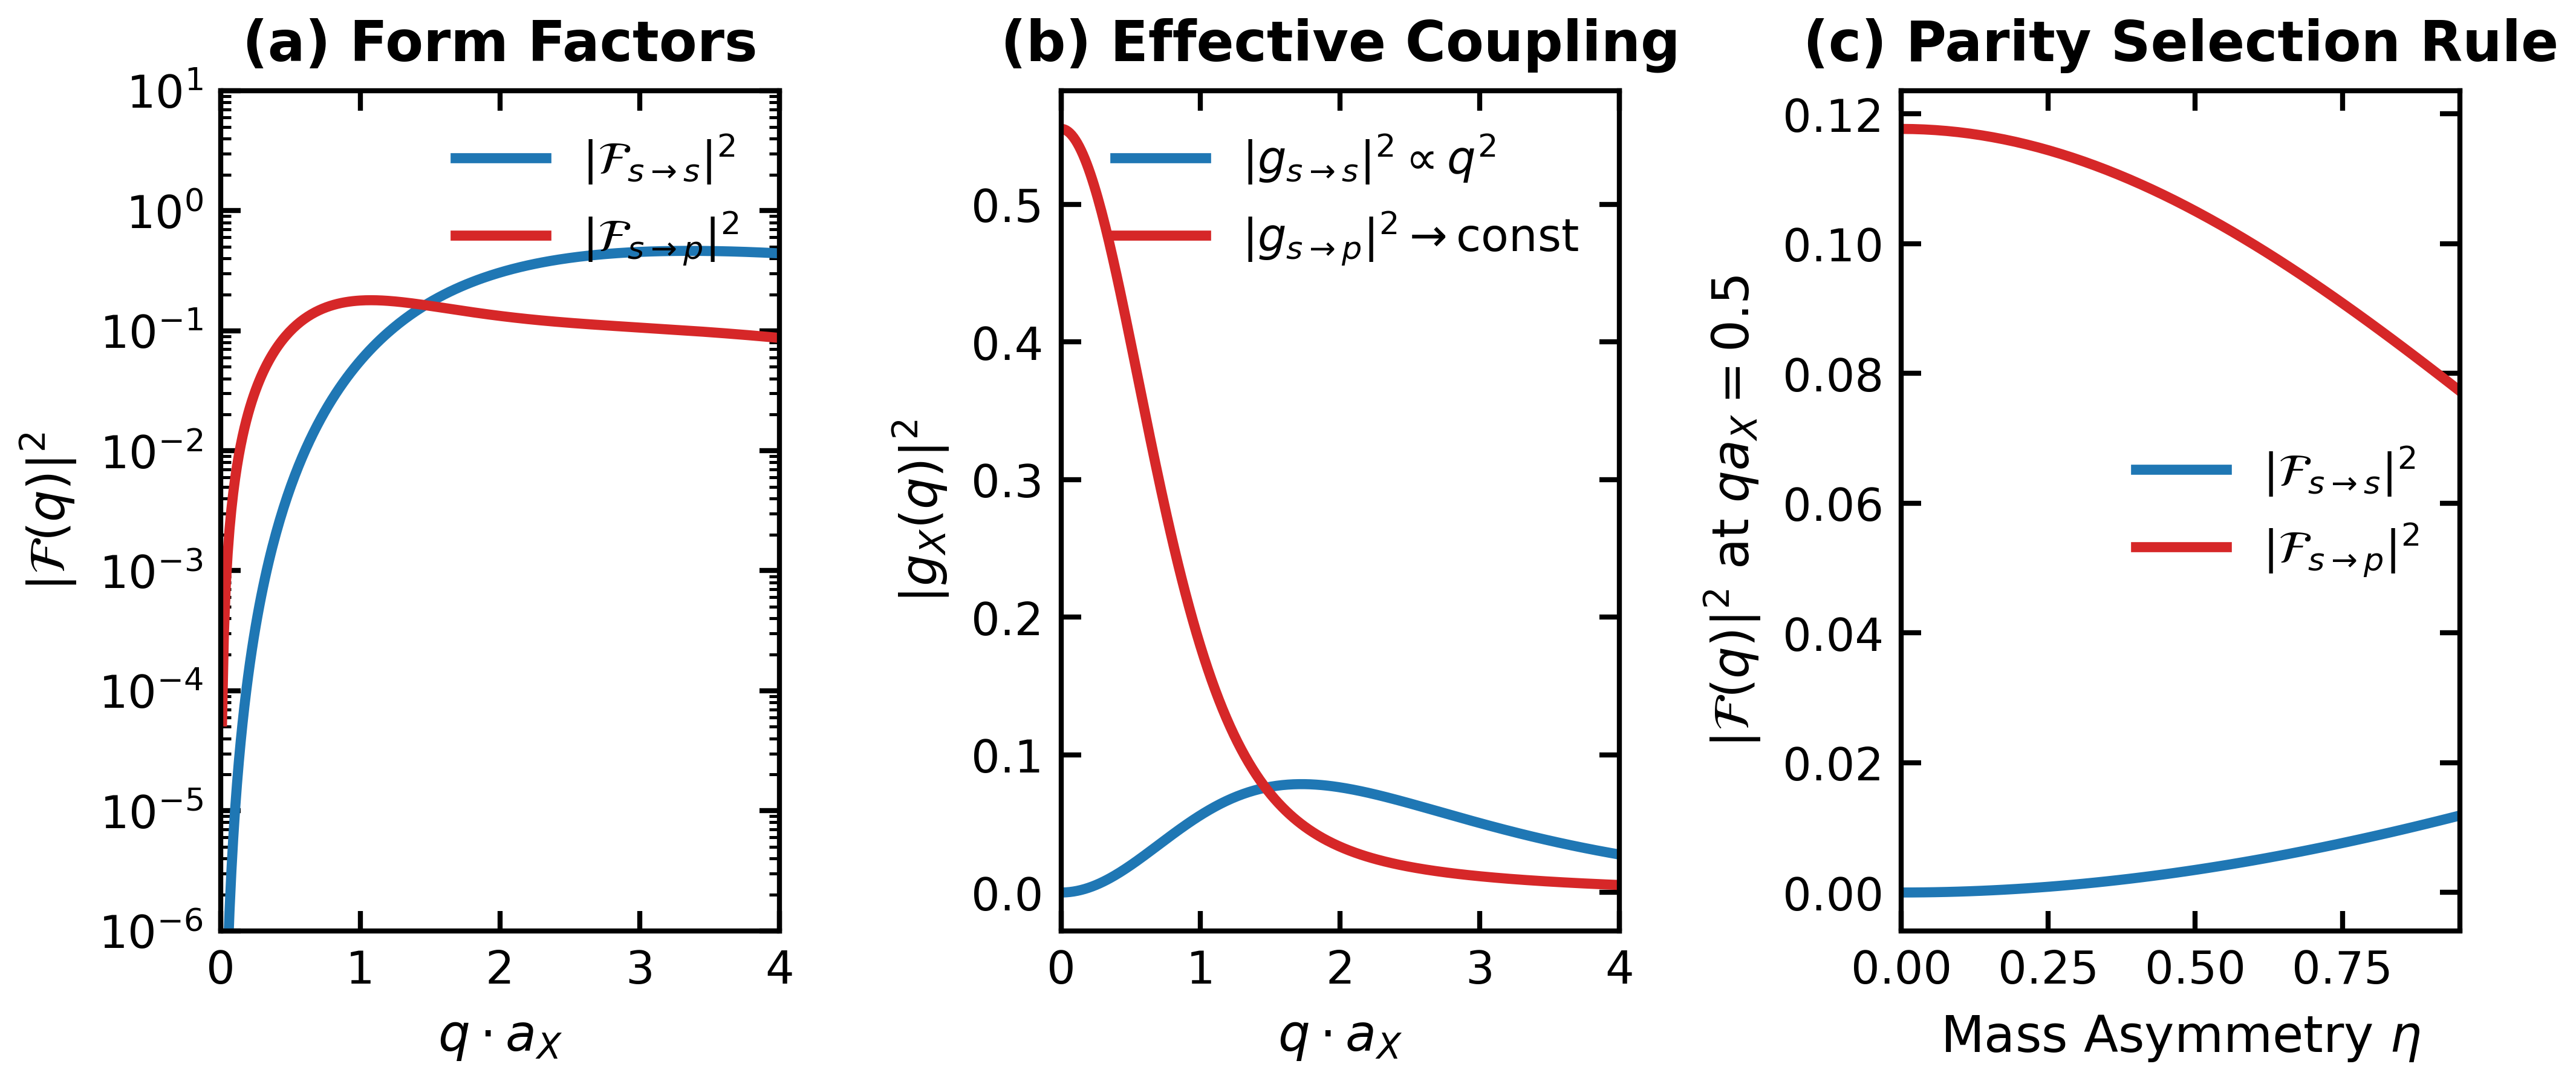

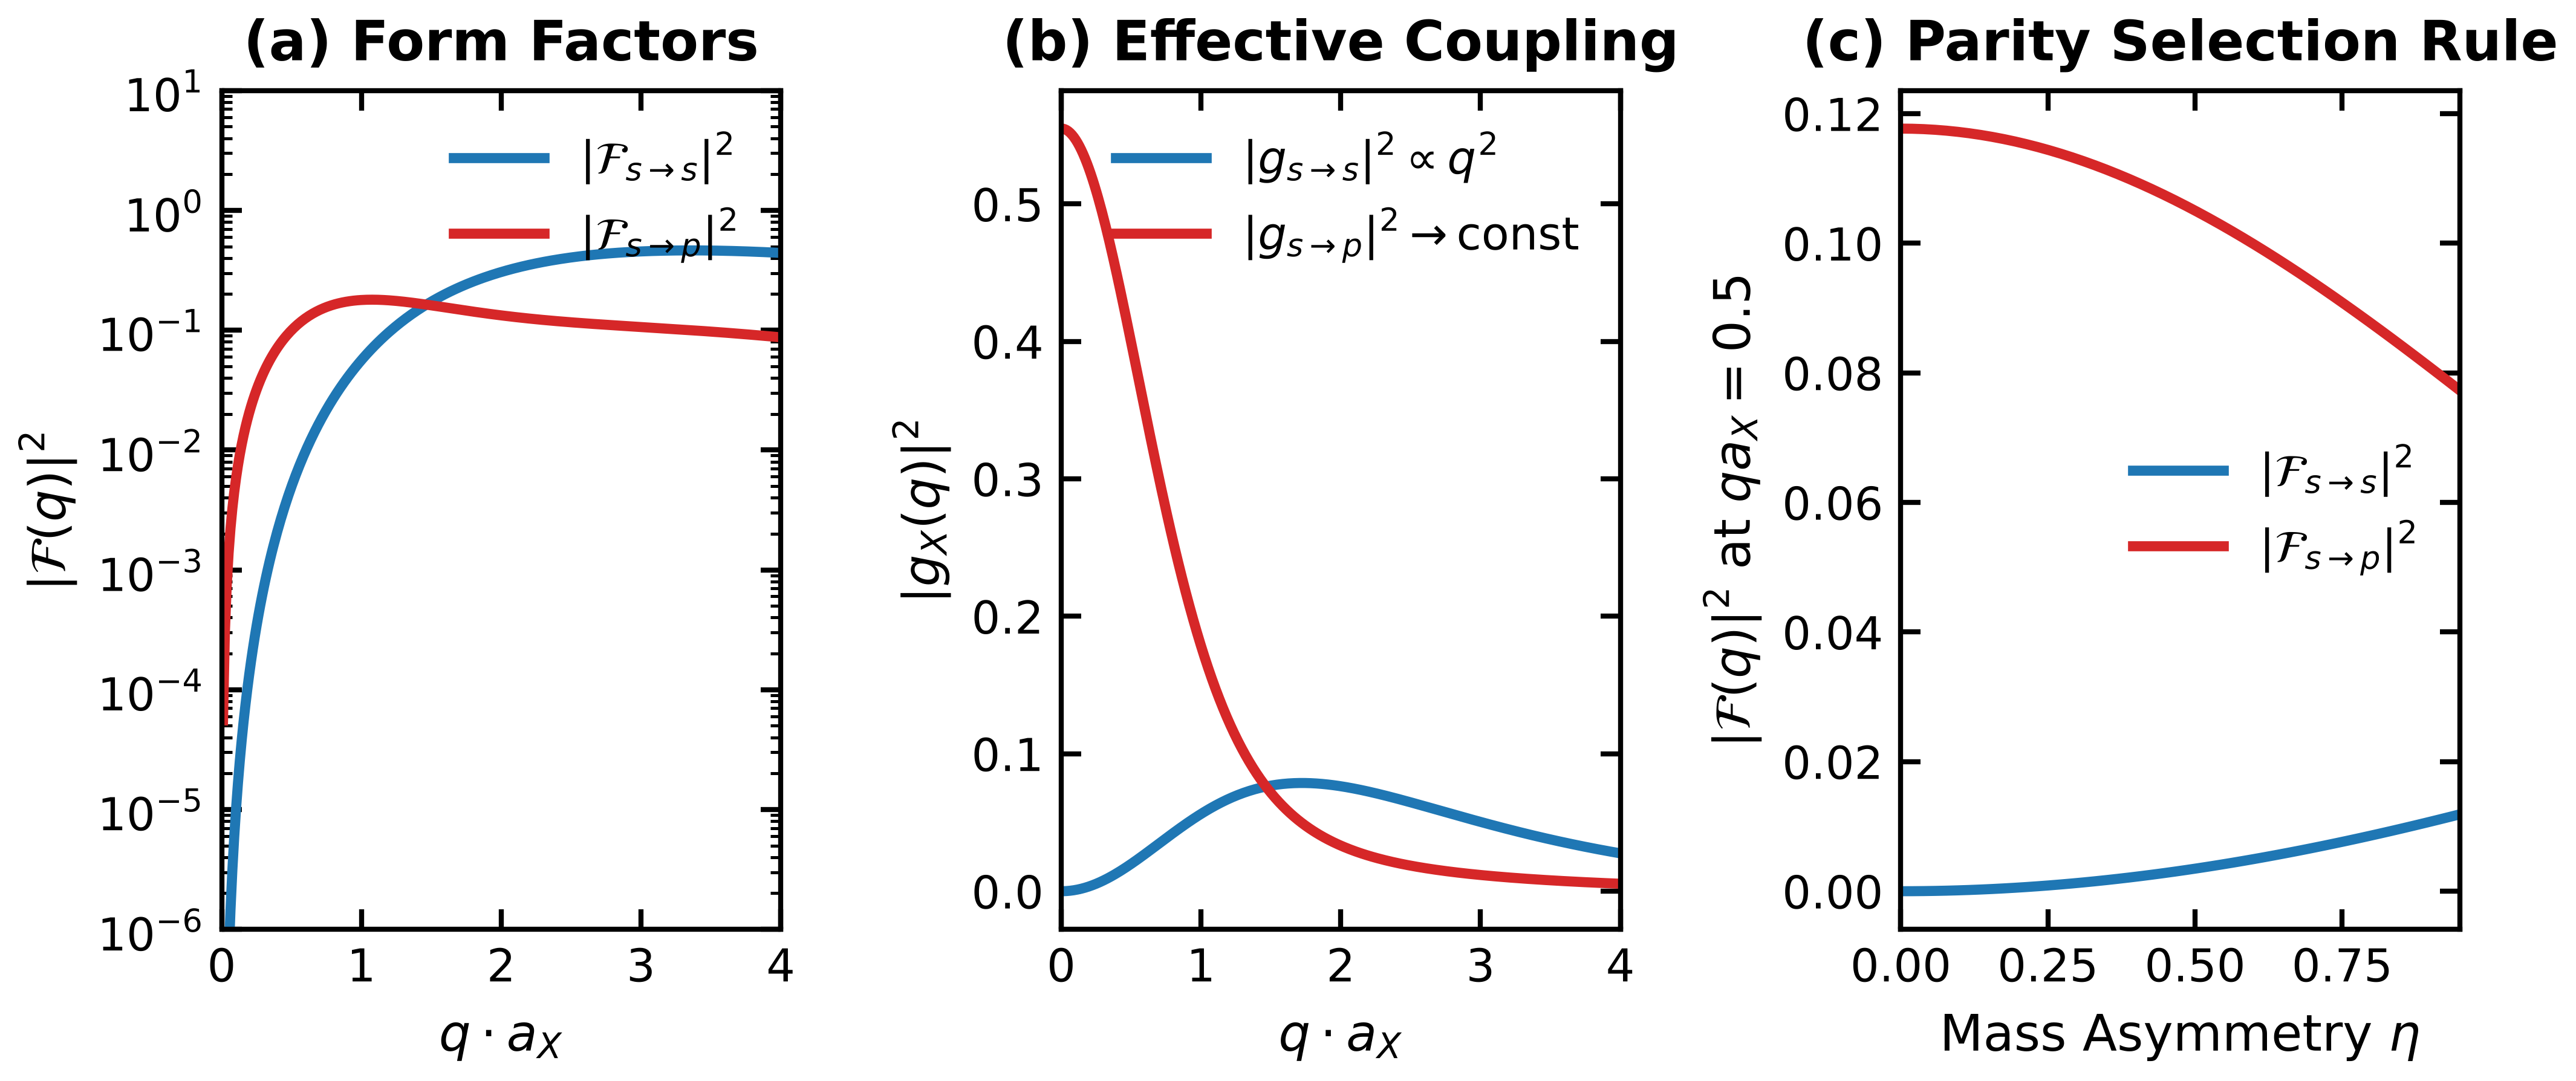

In [7]:
# ============================================================
# FIGURE 2: PARITY SELECTION RULE (high QUALITY)
# ============================================================

q_plot = np.linspace(0.01, 4.0, 300)
eta_demo = 0.6
alpha_h_demo = (1 + eta_demo) / 2.0
alpha_e_demo = (1 - eta_demo) / 2.0

Fss_q = np.array([F_1s_1s(q, alpha_e_demo, alpha_h_demo) for q in q_plot])
Fsp_q = np.array([F_1s_2p(q, alpha_e_demo, alpha_h_demo) for q in q_plot])

# --- Panel (a): Form Factors ---
fig, axes = highquality_figure(width='double', height_ratio=0.45, nrows=1, ncols=3)

ax = axes[0]
ax.plot(q_plot, np.abs(Fss_q)**2, '-', color='#1f77b4', lw=2.0,
        label=r'$|\mathcal{F}_{s\to s}|^2$')
ax.plot(q_plot, np.abs(Fsp_q)**2, '-', color='#d62728', lw=2.0,
        label=r'$|\mathcal{F}_{s\to p}|^2$')
ax.set_xlabel(r'$q \cdot a_X$')
ax.set_ylabel(r'$|\mathcal{F}(q)|^2$')
ax.set_yscale('log')
ax.set_ylim(1e-6, 1e1)
ax.set_xlim(0, 4.0)
ax.legend(loc='upper right')
ax.set_title('(a) Form Factors', fontsize=FONT_SIZE_TITLE)

# --- Panel (b): Effective Fröhlich Coupling ---
ax = axes[1]
g_ss = np.abs(Fss_q)**2 / (q_plot**2)
g_sp = np.abs(Fsp_q)**2 / (q_plot**2)

ax.plot(q_plot, g_ss, '-', color='#1f77b4', lw=2.0,
        label=r'$|g_{s\to s}|^2 \propto q^2$')
ax.plot(q_plot, g_sp, '-', color='#d62728', lw=2.0,
        label=r'$|g_{s\to p}|^2 \to \mathrm{const}$')
ax.set_xlabel(r'$q \cdot a_X$')
ax.set_ylabel(r'$|g_X(q)|^2$')
ax.set_xlim(0, 4.0)
ax.legend(loc='upper right')
ax.set_title('(b) Effective Coupling', fontsize=FONT_SIZE_TITLE)

# --- Panel (c): Parity Contrast vs eta ---
ax = axes[2]
etas_scan = np.linspace(0.0, 0.95, 50)
q_fixed = 0.5
Fss_scan = []
Fsp_scan = []

for eta in etas_scan:
    ah = (1 + eta) / 2.0
    ae = (1 - eta) / 2.0
    Fss_scan.append(F_1s_1s(q_fixed, ae, ah)**2)
    Fsp_scan.append(F_1s_2p(q_fixed, ae, ah)**2)

ax.plot(etas_scan, Fss_scan, '-', color='#1f77b4', lw=2.0,
        label=r'$|\mathcal{F}_{s\to s}|^2$')
ax.plot(etas_scan, Fsp_scan, '-', color='#d62728', lw=2.0,
        label=r'$|\mathcal{F}_{s\to p}|^2$')
ax.set_xlabel(r'Mass Asymmetry $\eta$')
ax.set_ylabel(r'$|\mathcal{F}(q)|^2$ at $q a_X = 0.5$')
ax.set_xlim(0, 0.95)
ax.legend(loc='center right')
ax.set_title('(c) Parity Selection Rule', fontsize=FONT_SIZE_TITLE)

plt.tight_layout(w_pad=1.5)
highquality_save(fig, 'figure2_parity_selection_rule.pdf')
highquality_save(fig, 'figure2_parity_selection_rule.png')
plt.show()

## Integrated dressing and Table III

$\lambda \propto \int_0^{\Lambda} dq\, |\mathcal F(q)|^2$ (the $q^2$ of the 3D measure cancels the $1/q^2$ of the Fröhlich vertex). Units of $a_X^{-1}$, common prefactor omitted.

In [8]:
Lambda_vals = np.logspace(-1, 1.2, 20)     # Lambda = q_max a_X, up to 15.85
etas = np.round(np.linspace(0.0, 0.9, 10), 10)
L_grid, Eta_grid = np.meshgrid(Lambda_vals, etas)
Lambda_ss = np.zeros_like(L_grid); Lambda_sp = np.zeros_like(L_grid)

for i, eta_i in enumerate(etas):
    e_, h_ = alphas(eta_i)
    for j, L in enumerate(Lambda_vals):
        Lambda_ss[i, j] = integrate.quad(lambda q: F_1s_1s(q, e_, h_)**2, 0, L, limit=200)[0]
        Lambda_sp[i, j] = integrate.quad(lambda q: F_1s_2p(q, e_, h_)**2, 0, L, limit=200)[0]

# Table III: select rows by eta VALUE (not by position in a sliced array)
jL = len(Lambda_vals) - 1
rows = []
print(f"Lambda = {Lambda_vals[jL]:.2f}")
print(f"{'eta':>5} {'lambda_ss':>10} {'lambda_sp':>10} {'sp/ss':>8}")
for eta_i in [0.0, 0.2, 0.4, 0.6, 0.8]:
    i = int(np.argmin(np.abs(etas - eta_i))); assert np.isclose(etas[i], eta_i)
    ss, sp = Lambda_ss[i, jL], Lambda_sp[i, jL]
    rows.append([eta_i, ss, sp])
    print(f"{eta_i:5.2f} {ss:10.4f} {sp:10.4f} {(sp/ss if ss > 0 else np.inf):8.2f}")
np.savetxt("table3_dressing.csv", rows, delimiter=",",
           header="eta,lambda_ss,lambda_sp (Lambda=15.85)", comments="")

Lambda = 15.85
  eta  lambda_ss  lambda_sp    sp/ss
 0.00     0.0000     0.6435      inf
 0.20     0.1949     0.6388     3.28
 0.40     0.8724     0.6348     0.73
 0.60     2.4719     0.6765     0.27
 0.80     6.7560     0.9221     0.14


## Figure 3: dressing versus exciton size and mass asymmetry

Saved: figure3_phase_diagram.pdf (7.0" x 3.9")
Saved: figure3_phase_diagram.png (7.0" x 3.9")


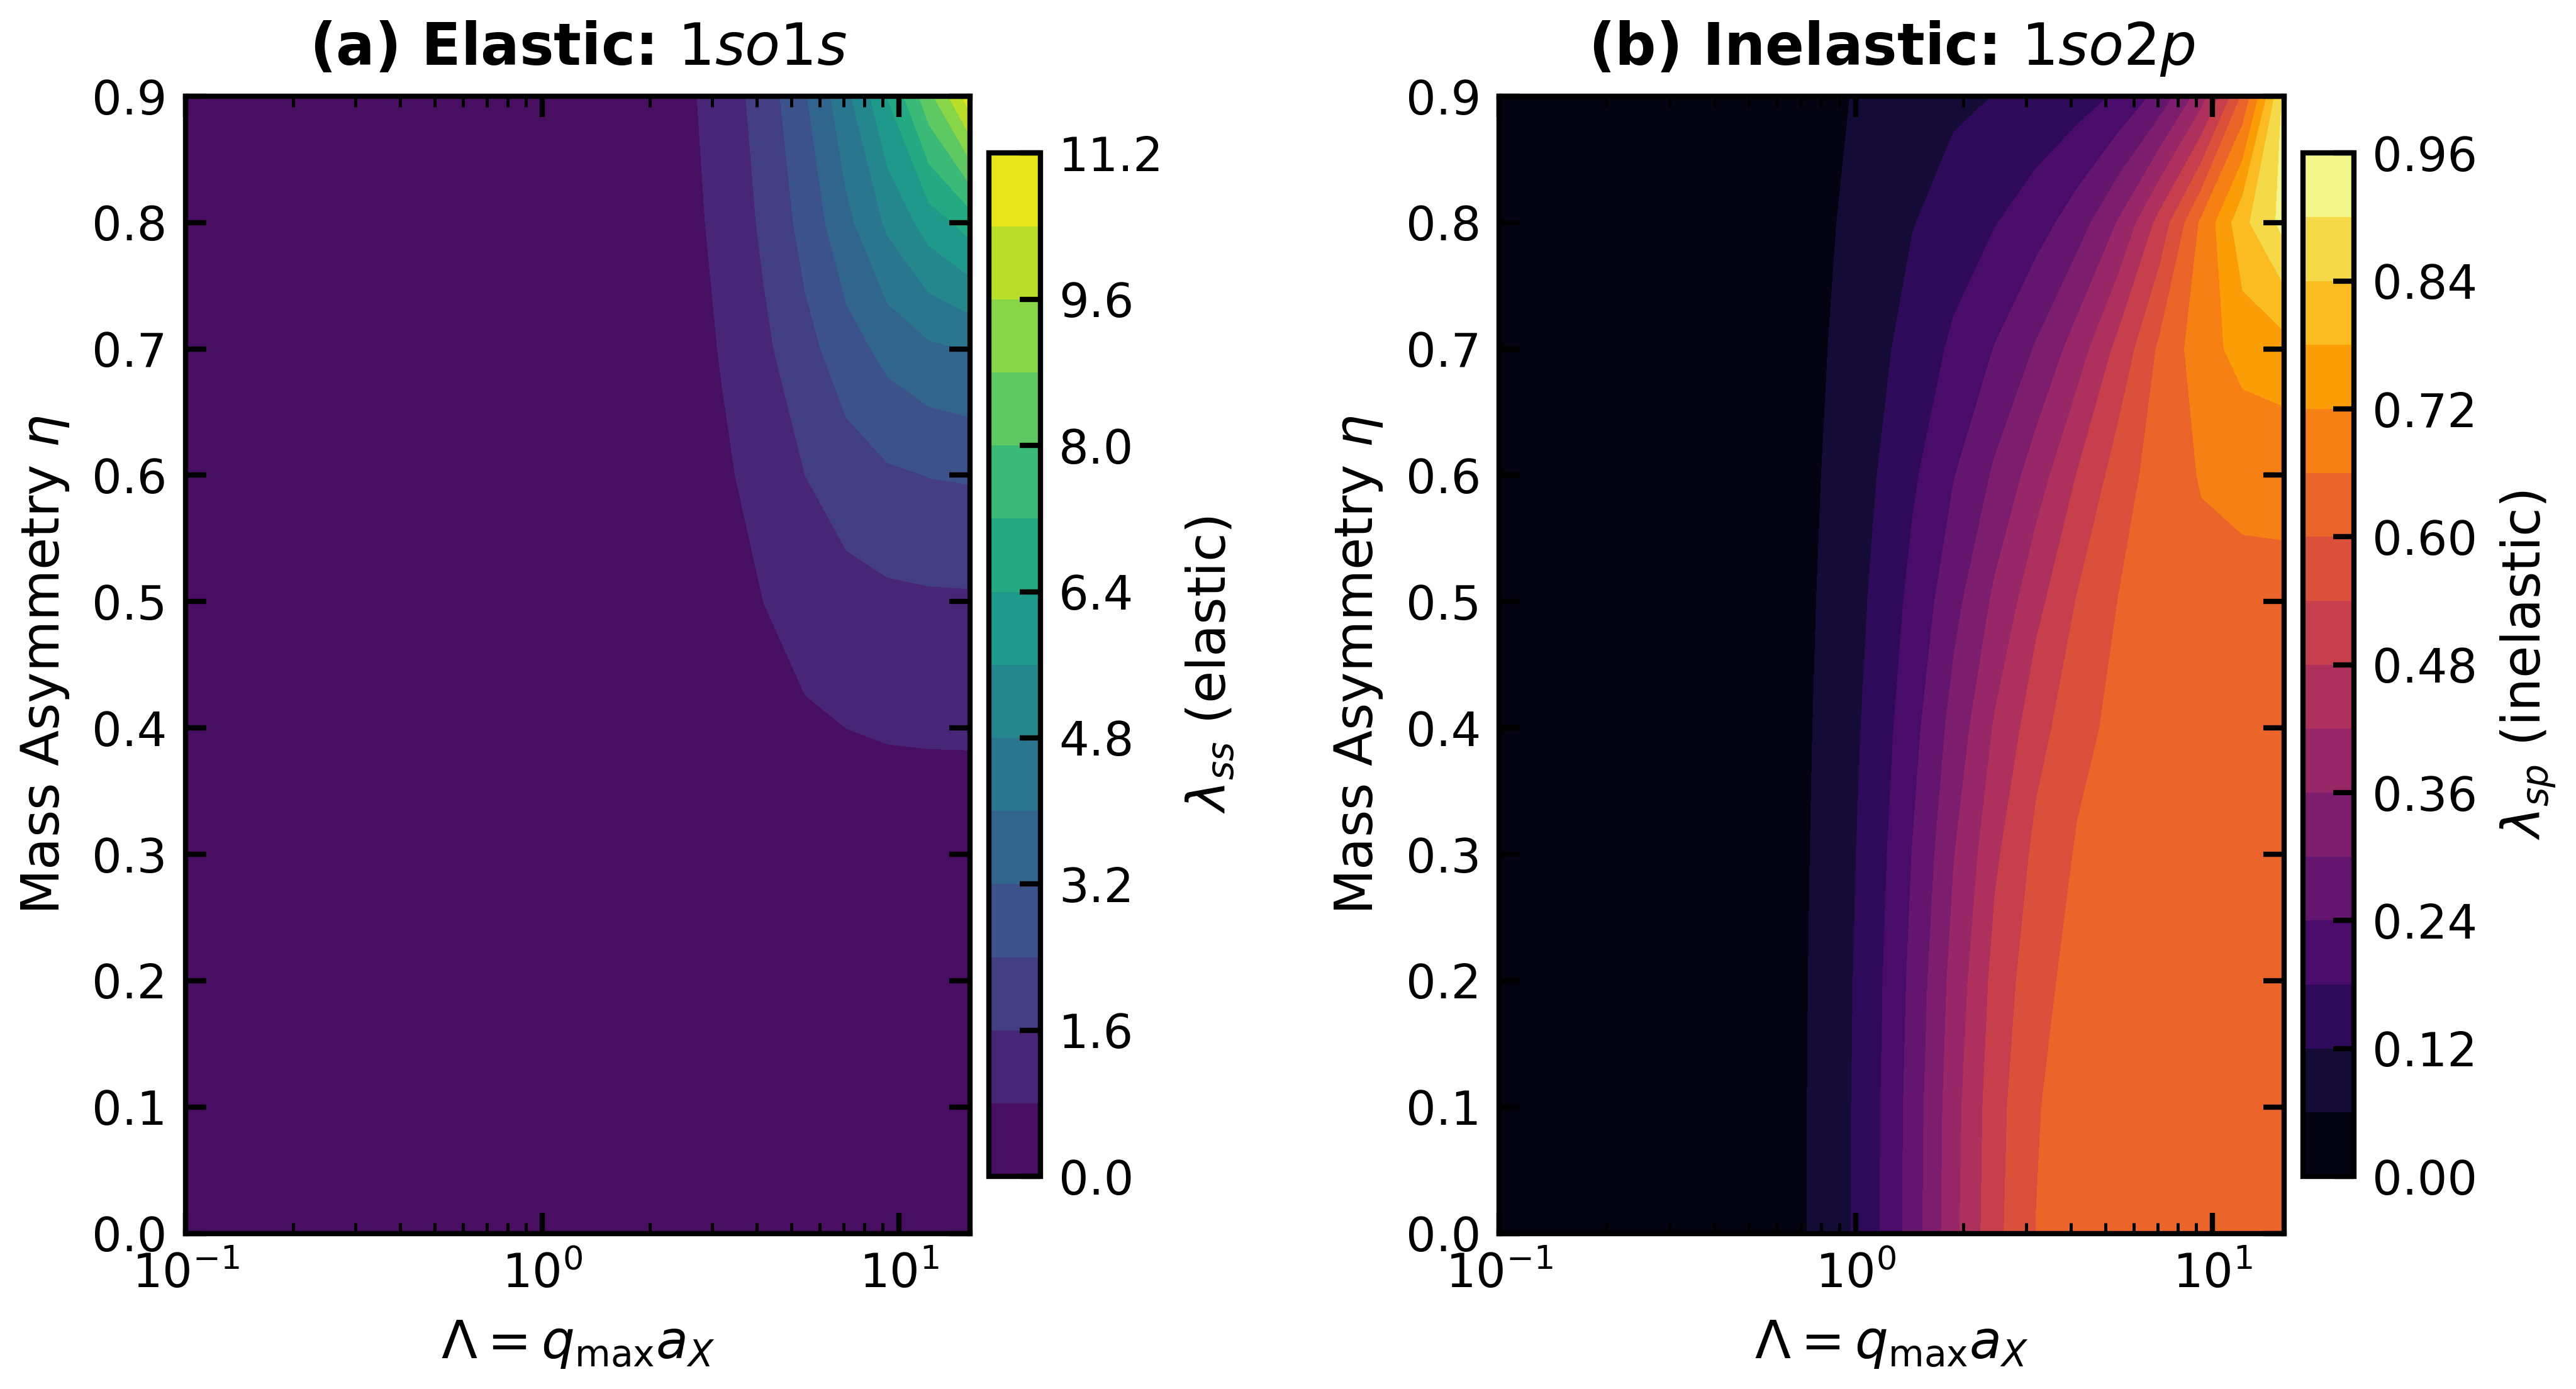

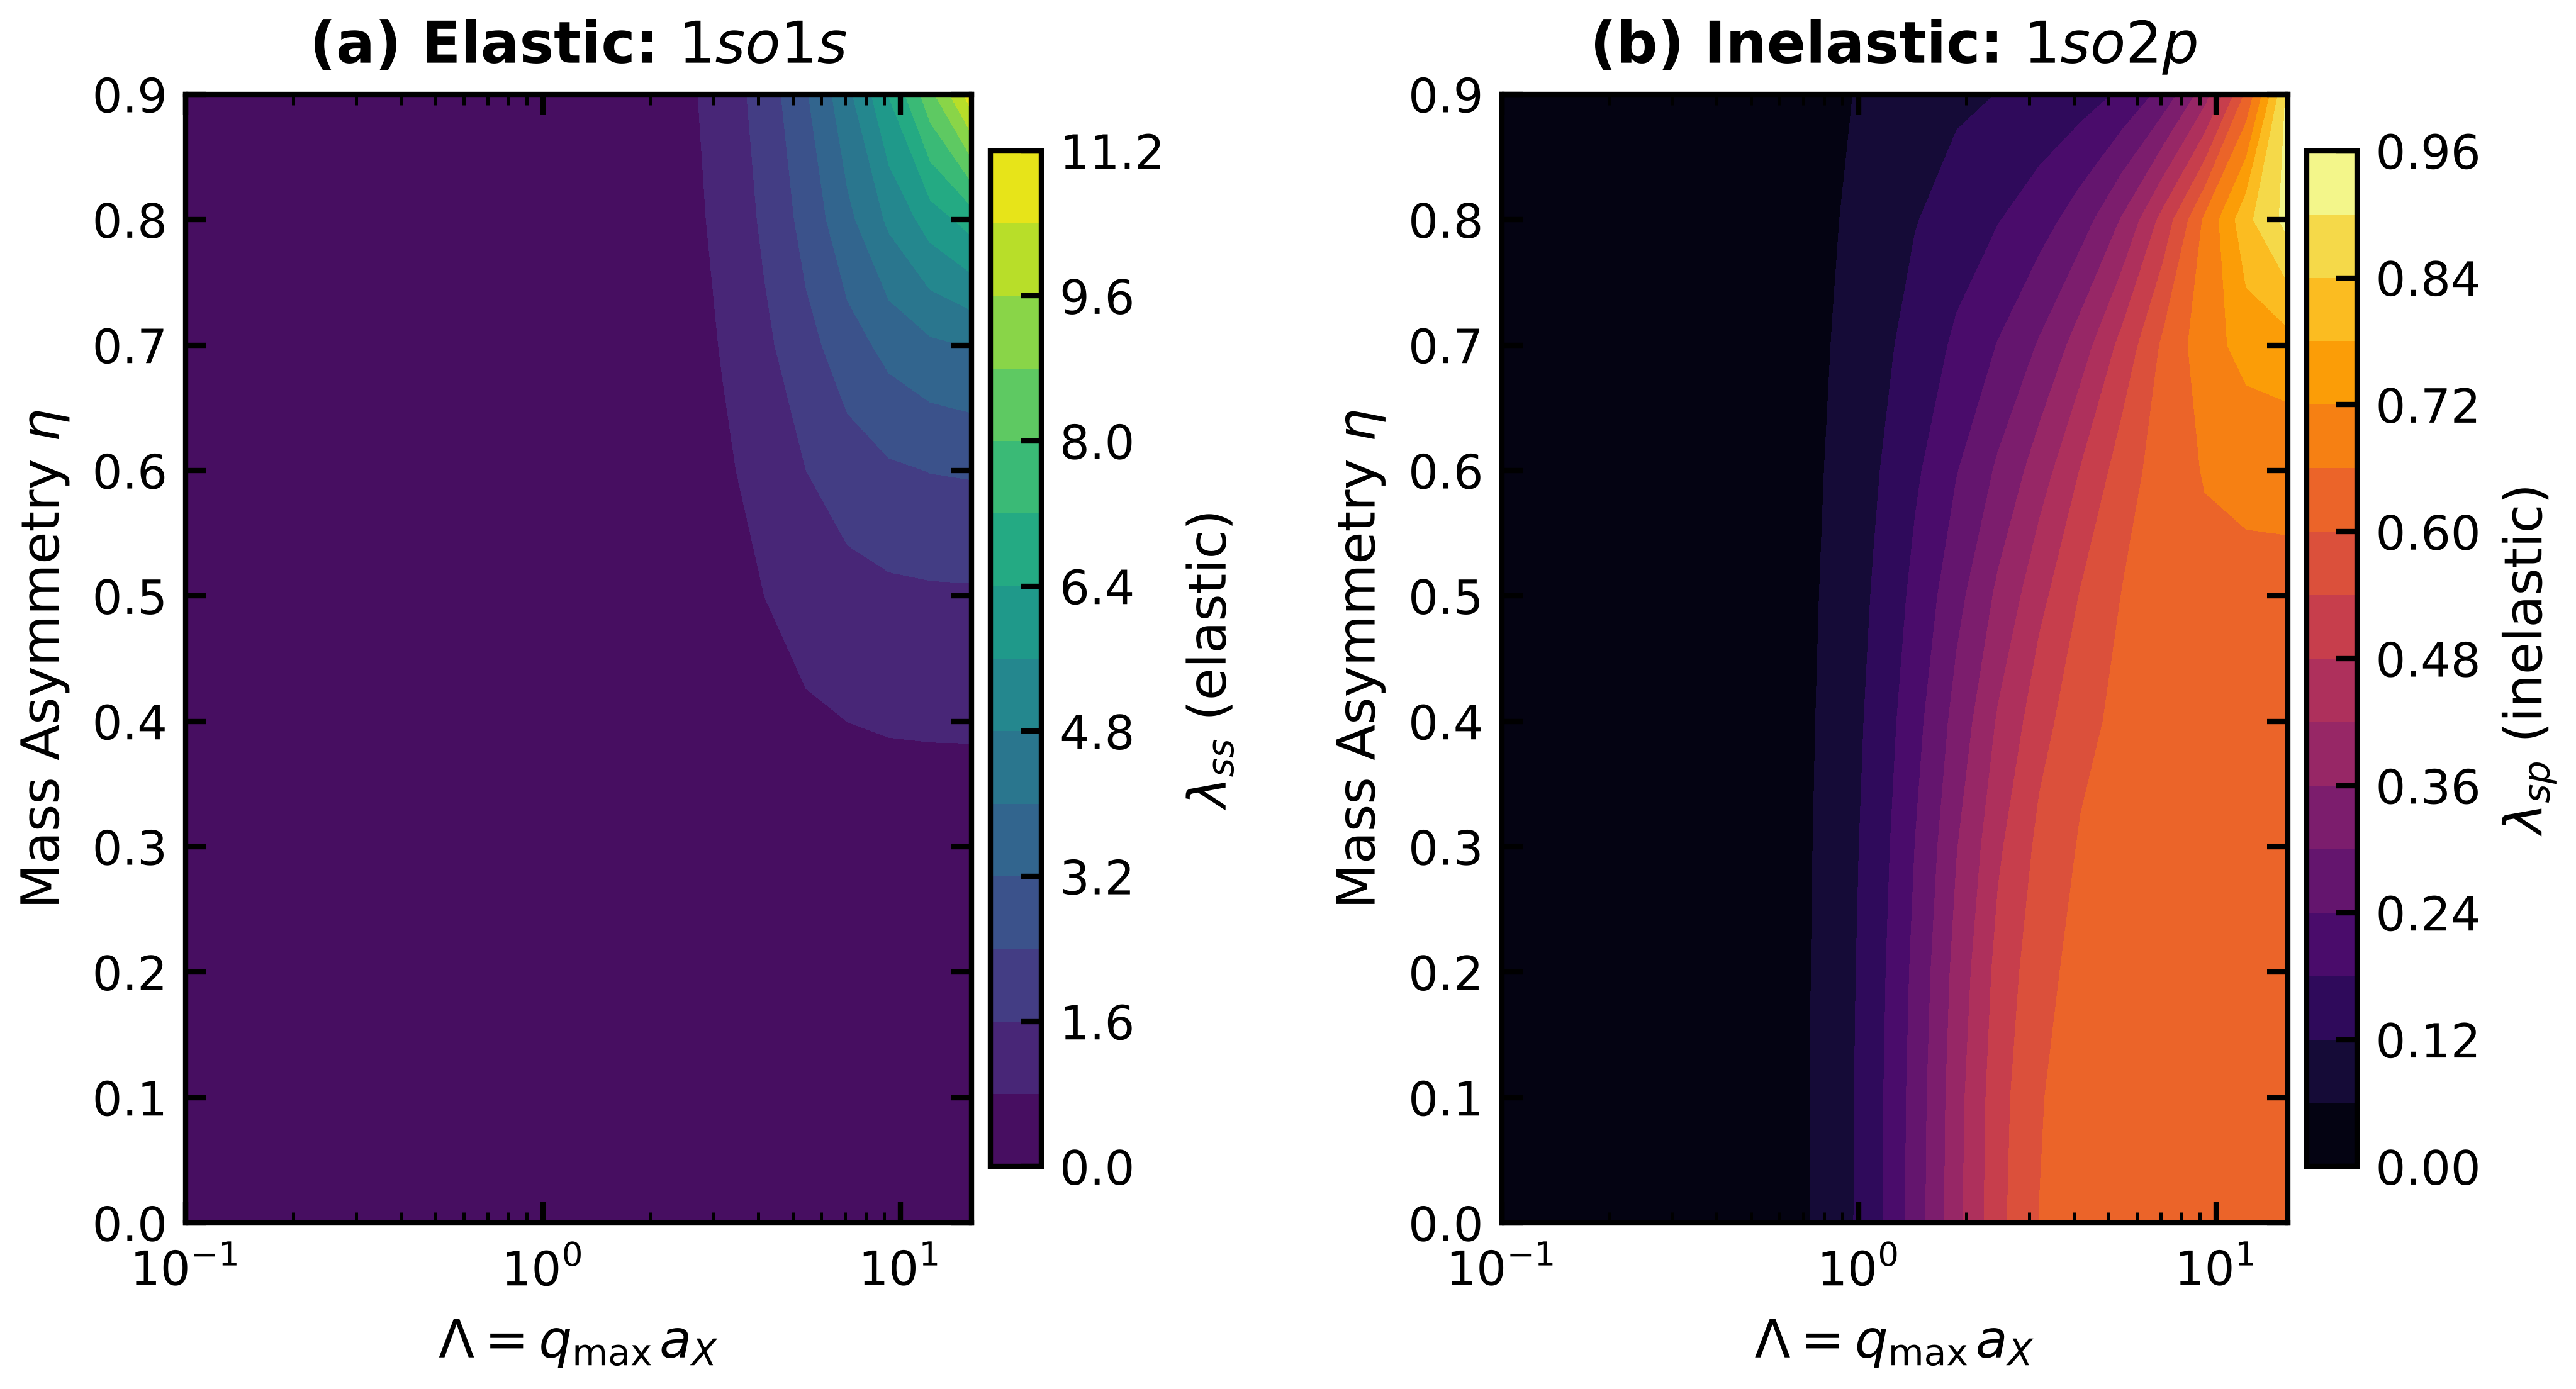

In [9]:
# ============================================================
# FIGURE 3: PHASE DIAGRAM (high QUALITY)
# ============================================================

fig, axes = highquality_figure(width='double', height_ratio=0.55, nrows=1, ncols=2)

# Panel (a): Elastic
ax = axes[0]
cf1 = ax.contourf(L_grid, Eta_grid, Lambda_ss, levels=15, cmap='viridis')
cb1 = fig.colorbar(cf1, ax=ax, shrink=0.9, pad=0.02)
cb1.set_label(r'$\lambda_{ss}$ (elastic)', fontsize=FONT_SIZE_LABEL)
ax.set_xlabel(r'$\Lambda = q_{\max} a_X$', fontsize=FONT_SIZE_LABEL)
ax.set_ylabel(r'Mass Asymmetry $\eta$', fontsize=FONT_SIZE_LABEL)
ax.set_xscale('log')
ax.set_title('(a) Elastic: $1s \to 1s$', fontsize=FONT_SIZE_TITLE)

# Panel (b): Inelastic
ax = axes[1]
cf2 = ax.contourf(L_grid, Eta_grid, Lambda_sp, levels=15, cmap='inferno')
cb2 = fig.colorbar(cf2, ax=ax, shrink=0.9, pad=0.02)
cb2.set_label(r'$\lambda_{sp}$ (inelastic)', fontsize=FONT_SIZE_LABEL)
ax.set_xlabel(r'$\Lambda = q_{\max} a_X$', fontsize=FONT_SIZE_LABEL)
ax.set_ylabel(r'Mass Asymmetry $\eta$', fontsize=FONT_SIZE_LABEL)
ax.set_xscale('log')
ax.set_title('(b) Inelastic: $1s \to 2p$', fontsize=FONT_SIZE_TITLE)

plt.tight_layout(w_pad=2.0)
highquality_save(fig, 'figure3_phase_diagram.pdf')
highquality_save(fig, 'figure3_phase_diagram.png')
plt.show()

# Part B: Huang-Rhys factor, COM recoil and materials

## Closed-form Huang-Rhys ratio $R(\eta)$ (symbolic)

With $g(k)=(1+k^2/4)^{-2}$, write $a=\alpha_e^2/4$, $b=\alpha_h^2/4$. Then
$S_X \propto \int_0^\infty [(1+ax^2)^{-2}-(1+bx^2)^{-2}]^2dx$ and
$S_{\rm ind}\propto\int_0^\infty[(1+ax^2)^{-4}+(1+bx^2)^{-4}]dx$.

In [10]:
import sympy as sp
x, a, b, eta_s = sp.symbols('x a b eta', positive=True)
I_aa = sp.integrate((1 + a*x**2)**-4, (x, 0, sp.oo))
I_ab = sp.integrate((1 + a*x**2)**-2 * (1 + b*x**2)**-2, (x, 0, sp.oo))
s, t = sp.symbols('s t', positive=True)              # s = sqrt(a) = alpha_e/2, t = sqrt(b) = alpha_h/2
R_sym = 1 - 2*I_ab.subs({a: s**2, b: t**2}) / (I_aa.subs(a, s**2) + I_aa.subs(a, t**2))
R_eta = sp.factor(sp.simplify(R_sym.subs({s: (1 - eta_s)/4, t: (1 + eta_s)/4})))
print("I_aa =", sp.simplify(I_aa))
print("R(eta) =", R_eta)
assert sp.simplify(R_eta - eta_s**2*(6 - eta_s**2)/5) == 0
F_ser = sp.series((1 + (1 - eta_s)**2*x**2/16)**-2 - (1 + (1 + eta_s)**2*x**2/16)**-2, x, 0, 6).removeO()
print("F_1s1s(x) small-x =", sp.factor(sp.expand(F_ser)))

I_aa = 5*pi/(32*sqrt(a))
R(eta) = -eta**2*(eta**2 - 6)/5
F_1s1s(x) small-x = -eta*x**2*(3*eta**2*x**2 + 3*x**2 - 16)/32


## Figure 4: numerical check of $R(\eta)$

max relative deviation from closed form: 2.8985702726913587e-12
Saved: figure4_suppression_law.pdf (3.5" x 2.6")
Saved: figure4_suppression_law.png (3.5" x 2.6")


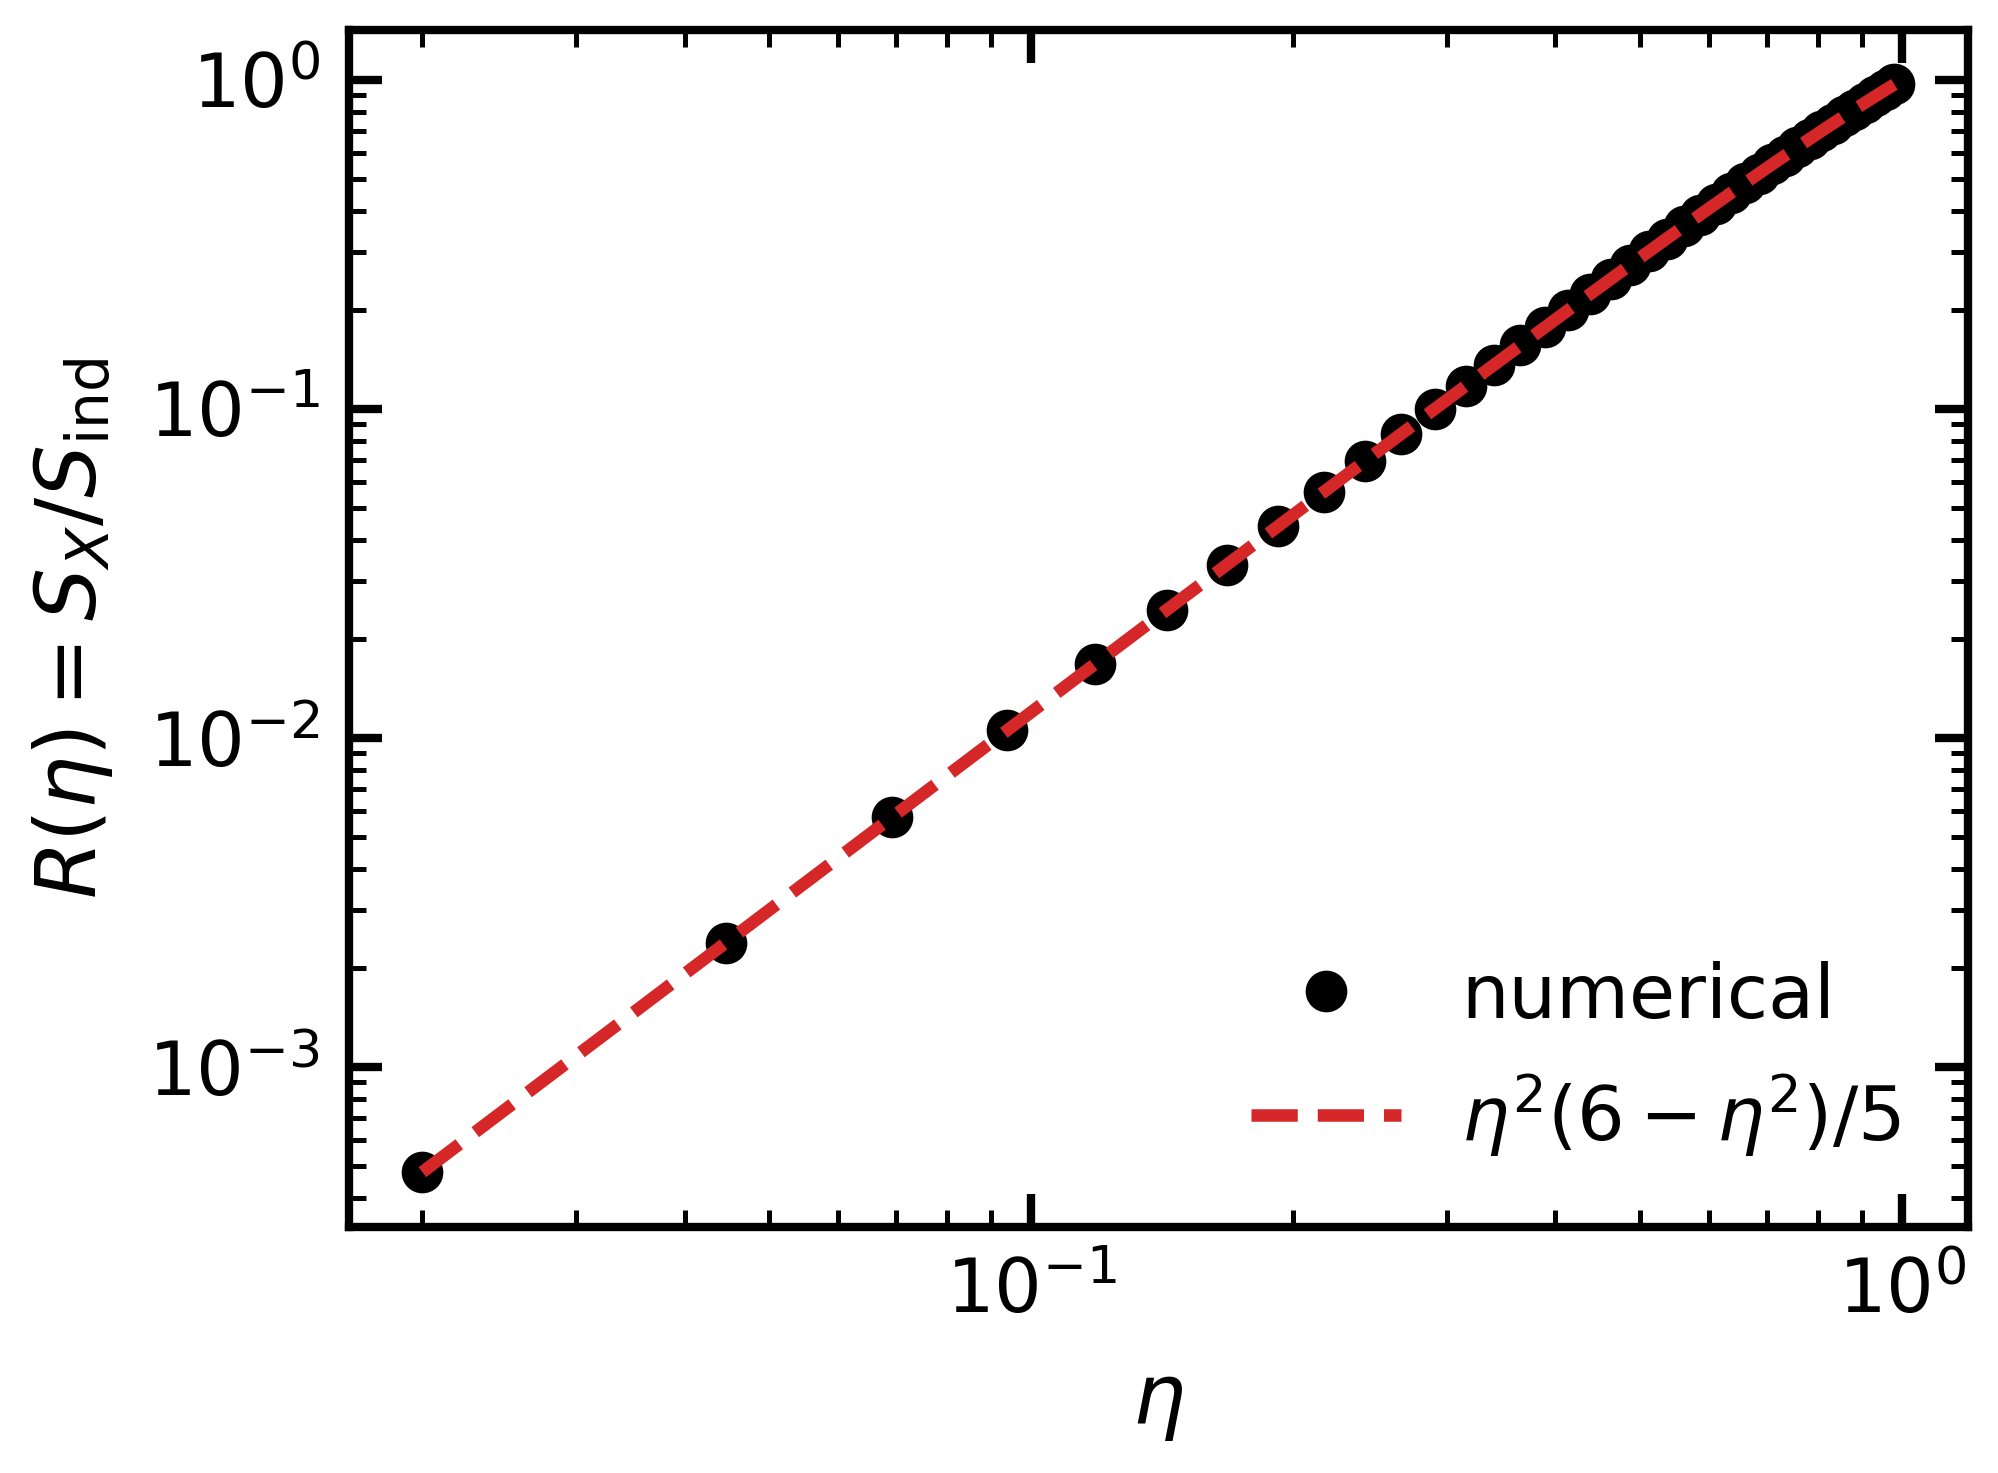

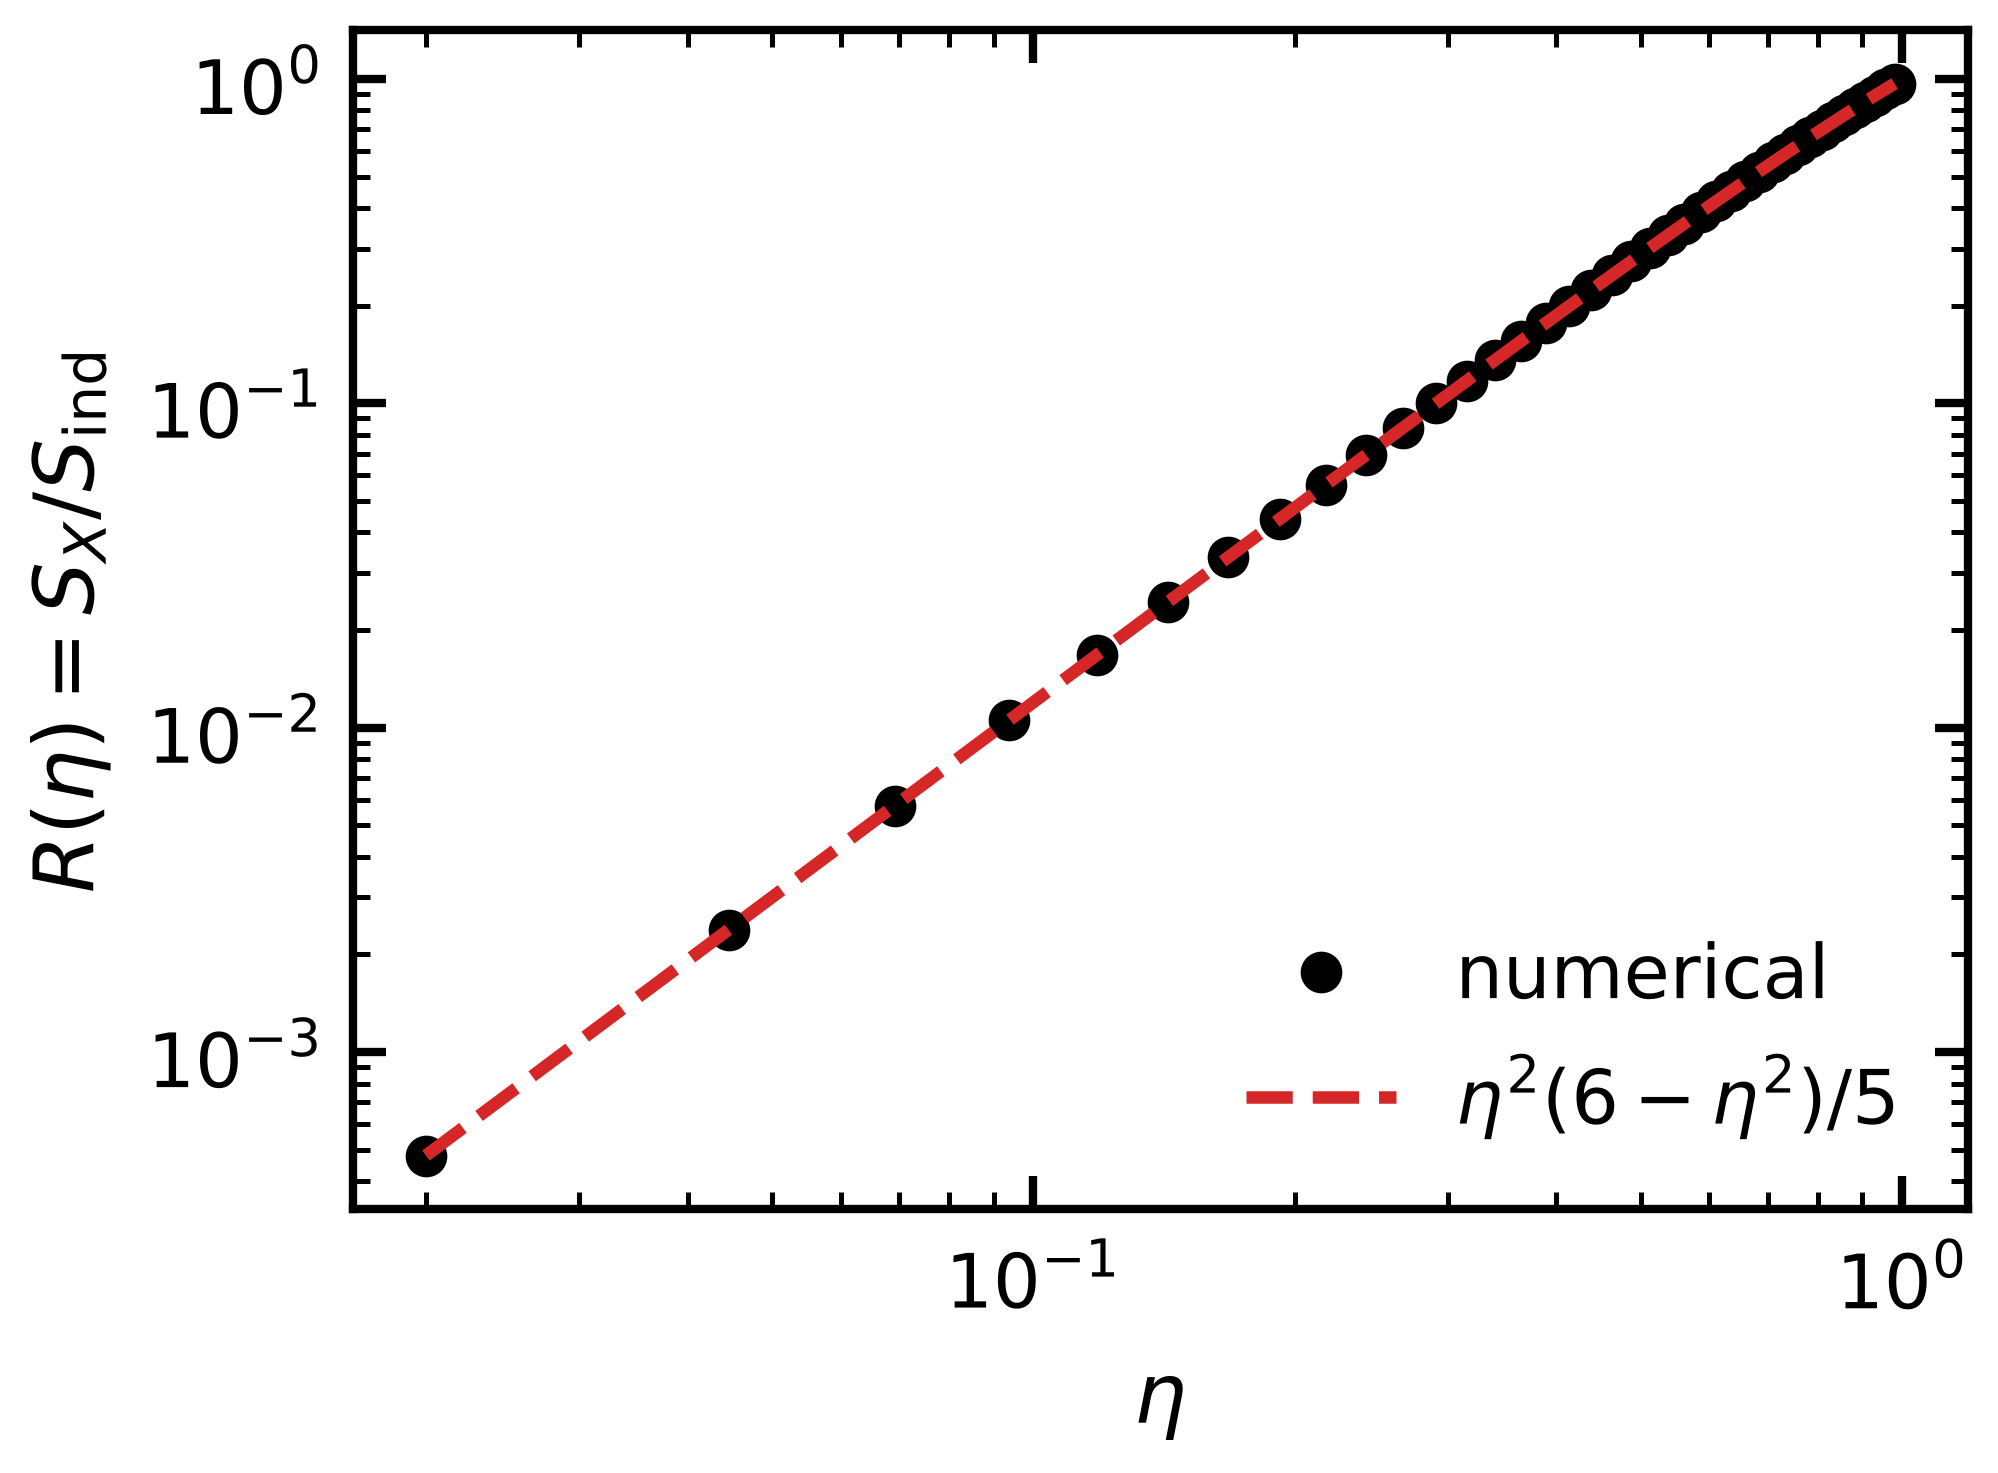

In [11]:
def R_num(eta_i):
    e_, h_ = alphas(eta_i)
    G = lambda k: (1 + k**2/4)**-2
    IX = integrate.quad(lambda q: (G(e_*q) - G(h_*q))**2, 0, np.inf, limit=500)[0]
    Ii = integrate.quad(lambda q: G(e_*q)**2 + G(h_*q)**2, 0, np.inf, limit=500)[0]
    return IX / Ii
eta_g = np.linspace(0.02, 0.98, 40)
R_g = np.array([R_num(v) for v in eta_g])
R_ex = eta_g**2*(6 - eta_g**2)/5
print("max relative deviation from closed form:", np.max(np.abs(R_g/R_ex - 1)))

fig, ax = highquality_figure(width='single')
ax.loglog(eta_g, R_g, 'o', ms=4, color='k', label='numerical')
ax.loglog(eta_g, R_ex, '--', color='#d62728', lw=1.5, label=r'$\eta^2(6-\eta^2)/5$')
ax.set_xlabel(r'$\eta$'); ax.set_ylabel(r'$R(\eta)=S_X/S_{\rm ind}$')
ax.legend(loc='lower right')
plt.tight_layout()
highquality_save(fig, 'figure4_suppression_law.pdf'); highquality_save(fig, 'figure4_suppression_law.png')
plt.show()

## Material parameters

The exciton Bohr radius is **derived** from the reduced mass and binding energy, $a_X = a_0\sqrt{{\rm Ry}/(\mu E_B)}$, so that $a_X$, $\mu$ and $E_B$ are mutually consistent. Check each entry against its source before publication.

In [12]:
# CODATA constants (SI)
e_, eps0, hbar, m0 = 1.602176634e-19, 8.8541878128e-12, 1.054571817e-34, 9.1093837015e-31
meV = 1e-3*e_; HBAR_MEV_S = hbar/meV
A0_NM, RY_MEV = 0.0529177210903, 13605.693122994
kB_meV = 8.617333262e-2   # meV/K

MATS = {
  # name:      m_e,   m_h,  eps_inf, eps_s, hw_LO(meV), E_B(meV), source note
  "GaAs":     dict(me=0.067, mh=0.45, einf=10.89, es=12.90, hw=36.3, EB=4.2,
                   note="standard GaAs values; E_B, hw_LO as in Rudin et al. 1990"),
  "MAPbI3":   dict(me=0.20,  mh=0.25, einf=6.5,   es=25.0,  hw=12.0, EB=16.0,
                   note="E_B: Miyata et al. 2015 (low-T). m_e, m_h: TODO cite source"),
  "FAPbI3":   dict(me=0.19,  mh=0.19, einf=None,  es=None,  hw=10.7, EB=14.0, inv=0.11,
                   note="mu=0.095, E_B=14 meV: Galkowski et al. 2016; m_e=m_h ASSUMED; inv_eps: TODO source"),
  "CsPbBr3":  dict(me=0.12,  mh=0.15, einf=None,  es=None,  hw=20.0, EB=33.0, inv=0.24,
                   note="TODO: cite masses, E_B and dielectric constants"),
}
EXP = {"GaAs": "8-14", "MAPbI3": "40", "FAPbI3": "27", "CsPbBr3": "~70"}
EXP_MID = {"GaAs": 11.0, "MAPbI3": 40.0, "FAPbI3": 27.0, "CsPbBr3": 70.0}

def inv_eps(p):
    return p["inv"] if p.get("einf") is None else 1/p["einf"] - 1/p["es"]
def mu(p): return p["me"]*p["mh"]/(p["me"] + p["mh"])
def aX_nm(p): return A0_NM*np.sqrt(RY_MEV/(mu(p)*p["EB"]))
def eta_of(p): return (p["mh"] - p["me"])/(p["mh"] + p["me"])
def frohlich_alpha(m, hw, inv):
    return e_**2/(4*np.pi*eps0*hbar)*inv*np.sqrt(m*m0/(2*hw*meV))

for k, p in MATS.items():
    print(f"{k:8s} mu={mu(p):.4f}  a_X={aX_nm(p):5.2f} nm  eta={eta_of(p):+.3f}  "
          f"inv_eps={inv_eps(p):.4f}  alpha_e={frohlich_alpha(p['me'],p['hw'],inv_eps(p)):.3f}  | {p['note']}")

GaAs     mu=0.0583  a_X=12.47 nm  eta=+0.741  inv_eps=0.0143  alpha_e=0.072  | standard GaAs values; E_B, hw_LO as in Rudin et al. 1990
MAPbI3   mu=0.1111  a_X= 4.63 nm  eta=+0.111  inv_eps=0.1138  alpha_e=1.714  | E_B: Miyata et al. 2015 (low-T). m_e, m_h: TODO cite source
FAPbI3   mu=0.0950  a_X= 5.35 nm  eta=+0.000  inv_eps=0.1100  alpha_e=1.710  | mu=0.095, E_B=14 meV: Galkowski et al. 2016; m_e=m_h ASSUMED; inv_eps: TODO source
CsPbBr3  mu=0.0667  a_X= 4.16 nm  eta=+0.111  inv_eps=0.2400  alpha_e=2.168  | TODO: cite masses, E_B and dielectric constants


## Recoil linewidth coefficient and Huang-Rhys factors

$\gamma_{\rm LO}^{\rm recoil} = \frac{2\pi}{\hbar}\frac{q_*^2}{2\pi^2}\frac{|\tilde V(q_*)|^2|\mathcal F_{1s,1s}(q_*)|^2}{\hbar v_*}$, with $q_*=\sqrt{2M\hbar\omega_{\rm LO}}/\hbar$, $v_*=\hbar q_*/M$ and $|\tilde V|^2 = \frac{e^2}{4\pi\varepsilon_0}\frac{2\pi\hbar\omega_{\rm LO}}{q^2}(\varepsilon_\infty^{-1}-\varepsilon_s^{-1})$. Reported as $\hbar\times$rate in meV.

$S = \frac{e^2}{4\pi\varepsilon_0}\frac{\varepsilon_\infty^{-1}-\varepsilon_s^{-1}}{\pi\hbar\omega_{\rm LO}}\int_0^\infty dq\,|\mathcal F(q)|^2$.

In [13]:
G1s = lambda k: (1 + k**2/4)**-2      # k in units of 1/a_X

def recoil(me, mh, hw, aX, inv):
    "returns gamma_LO^recoil (meV), q* a_X, F(q*), eta"
    a = aX*1e-9; M = (me + mh)*m0; hwJ = hw*meV
    qs = np.sqrt(2*M*hwJ)/hbar
    ae, ah = me/(me + mh), mh/(me + mh)
    F = G1s(ae*qs*a) - G1s(ah*qs*a)
    V2 = e_**2/(4*np.pi*eps0) * 2*np.pi*hwJ*inv/qs**2
    rate = (2*np.pi/hbar) * V2 * F**2 * qs*M/(2*np.pi**2*hbar**2)
    return rate*HBAR_MEV_S, qs*a, F, (mh - me)/(me + mh)

def huang_rhys(me, mh, hw, aX, inv):
    ae, ah = me/(me + mh), mh/(me + mh)
    P = e_**2/(4*np.pi*eps0) * inv/(np.pi*hw*meV) / (aX*1e-9)
    IX = integrate.quad(lambda x: (G1s(ae*x) - G1s(ah*x))**2, 0, np.inf, limit=500)[0]
    Ii = integrate.quad(lambda x: G1s(ae*x)**2 + G1s(ah*x)**2, 0, np.inf, limit=500)[0]
    return P*IX, P*Ii

rows = []
print(f"{'':8s} {'eta':>6} {'aX(nm)':>7} {'q*aX':>6} {'F(q*)':>7} {'gamma(meV)':>10} {'exp(meV)':>9}")
for k, p in MATS.items():
    g, qa, F, et = recoil(p["me"], p["mh"], p["hw"], aX_nm(p), inv_eps(p))
    rows.append([k, et, aX_nm(p), qa, F, g, EXP[k]])
    print(f"{k:8s} {et:6.2f} {aX_nm(p):7.2f} {qa:6.2f} {F:7.3f} {g:10.3f} {EXP[k]:>9}")
import csv
with open("table4_recoil.csv", "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["material","eta","aX_nm","qstar_aX","F_qstar","gamma_recoil_meV","gamma_exp_meV"])
    w.writerows(rows)

p = MATS["MAPbI3"]
SX, Sind = huang_rhys(p["me"], p["mh"], p["hw"], aX_nm(p), inv_eps(p))
print(f"\nMAPbI3: S_ind = {Sind:.2f}, S_X = {SX:.3f}, ratio = {SX/Sind:.4f} "
      f"(closed form R = {eta_of(p)**2*(6-eta_of(p)**2)/5:.4f}); "
      f"ZPL weight exp(-S_X) = {np.exp(-SX):.3f}, exp(-S_ind) = {np.exp(-Sind):.4f}")

            eta  aX(nm)   q*aX   F(q*) gamma(meV)  exp(meV)
GaAs       0.74   12.47   8.75   0.568      4.670      8-14
MAPbI3     0.11    4.63   1.74   0.100      0.615        40
FAPbI3     0.00    5.35   1.75   0.000      0.000        27
CsPbBr3    0.11    4.16   1.57   0.089      1.021       ~70

MAPbI3: S_ind = 3.73, S_X = 0.055, ratio = 0.0148 (closed form R = 0.0148); ZPL weight exp(-S_X) = 0.946, exp(-S_ind) = 0.0239


## Sensitivity of the perovskite recoil coefficients

Worst case over $a_X\in[2,7]$ nm and $|\eta|\le0.2$, with the total mass, $\hbar\omega_{\rm LO}$ and dielectric factor of each material fixed.

In [14]:
for k in ["MAPbI3", "FAPbI3", "CsPbBr3"]:
    p = MATS[k]; Mt = p["me"] + p["mh"]
    worst = max(recoil(Mt/2*(1 - et), Mt/2*(1 + et), p["hw"], ax, inv_eps(p))[0]
                for ax in np.linspace(2, 7, 51) for et in np.linspace(0, 0.2, 21))
    print(f"{k:8s} max gamma_recoil = {worst:.2f} meV   (experiment {EXP[k]} meV)")

MAPbI3   max gamma_recoil = 3.37 meV   (experiment 40 meV)
FAPbI3   max gamma_recoil = 2.54 meV   (experiment 27 meV)
CsPbBr3  max gamma_recoil = 7.11 meV   (experiment ~70 meV)


## Kinematics of the other single-LO absorption channels

With recoil, $1s\to np$ absorption requires $\hbar\omega_{\rm LO} > \Delta E_{np} = E_B(1-1/n^2)$ (lowest: $\frac34E_B$), and ionization requires $\hbar\omega_{\rm LO}>E_B$.

In [15]:
print(f"{'':8s} {'E_B':>6} {'3E_B/4':>7} {'hw_LO':>6}  1s->2p  ionization")
for k, p in MATS.items():
    print(f"{k:8s} {p['EB']:6.1f} {0.75*p['EB']:7.2f} {p['hw']:6.1f}  "
          f"{'open' if p['hw'] > 0.75*p['EB'] else 'closed':6s}  {'open' if p['hw'] > p['EB'] else 'closed'}")

            E_B  3E_B/4  hw_LO  1s->2p  ionization
GaAs        4.2    3.15   36.3  open    open
MAPbI3     16.0   12.00   12.0  closed  closed
FAPbI3     14.0   10.50   10.7  open    closed
CsPbBr3    33.0   24.75   20.0  closed  closed


## Figure 5: recoil coefficient versus mass asymmetry

Saved: figure5_recoil_vs_eta.pdf (3.5" x 2.6")
Saved: figure5_recoil_vs_eta.png (3.5" x 2.6")


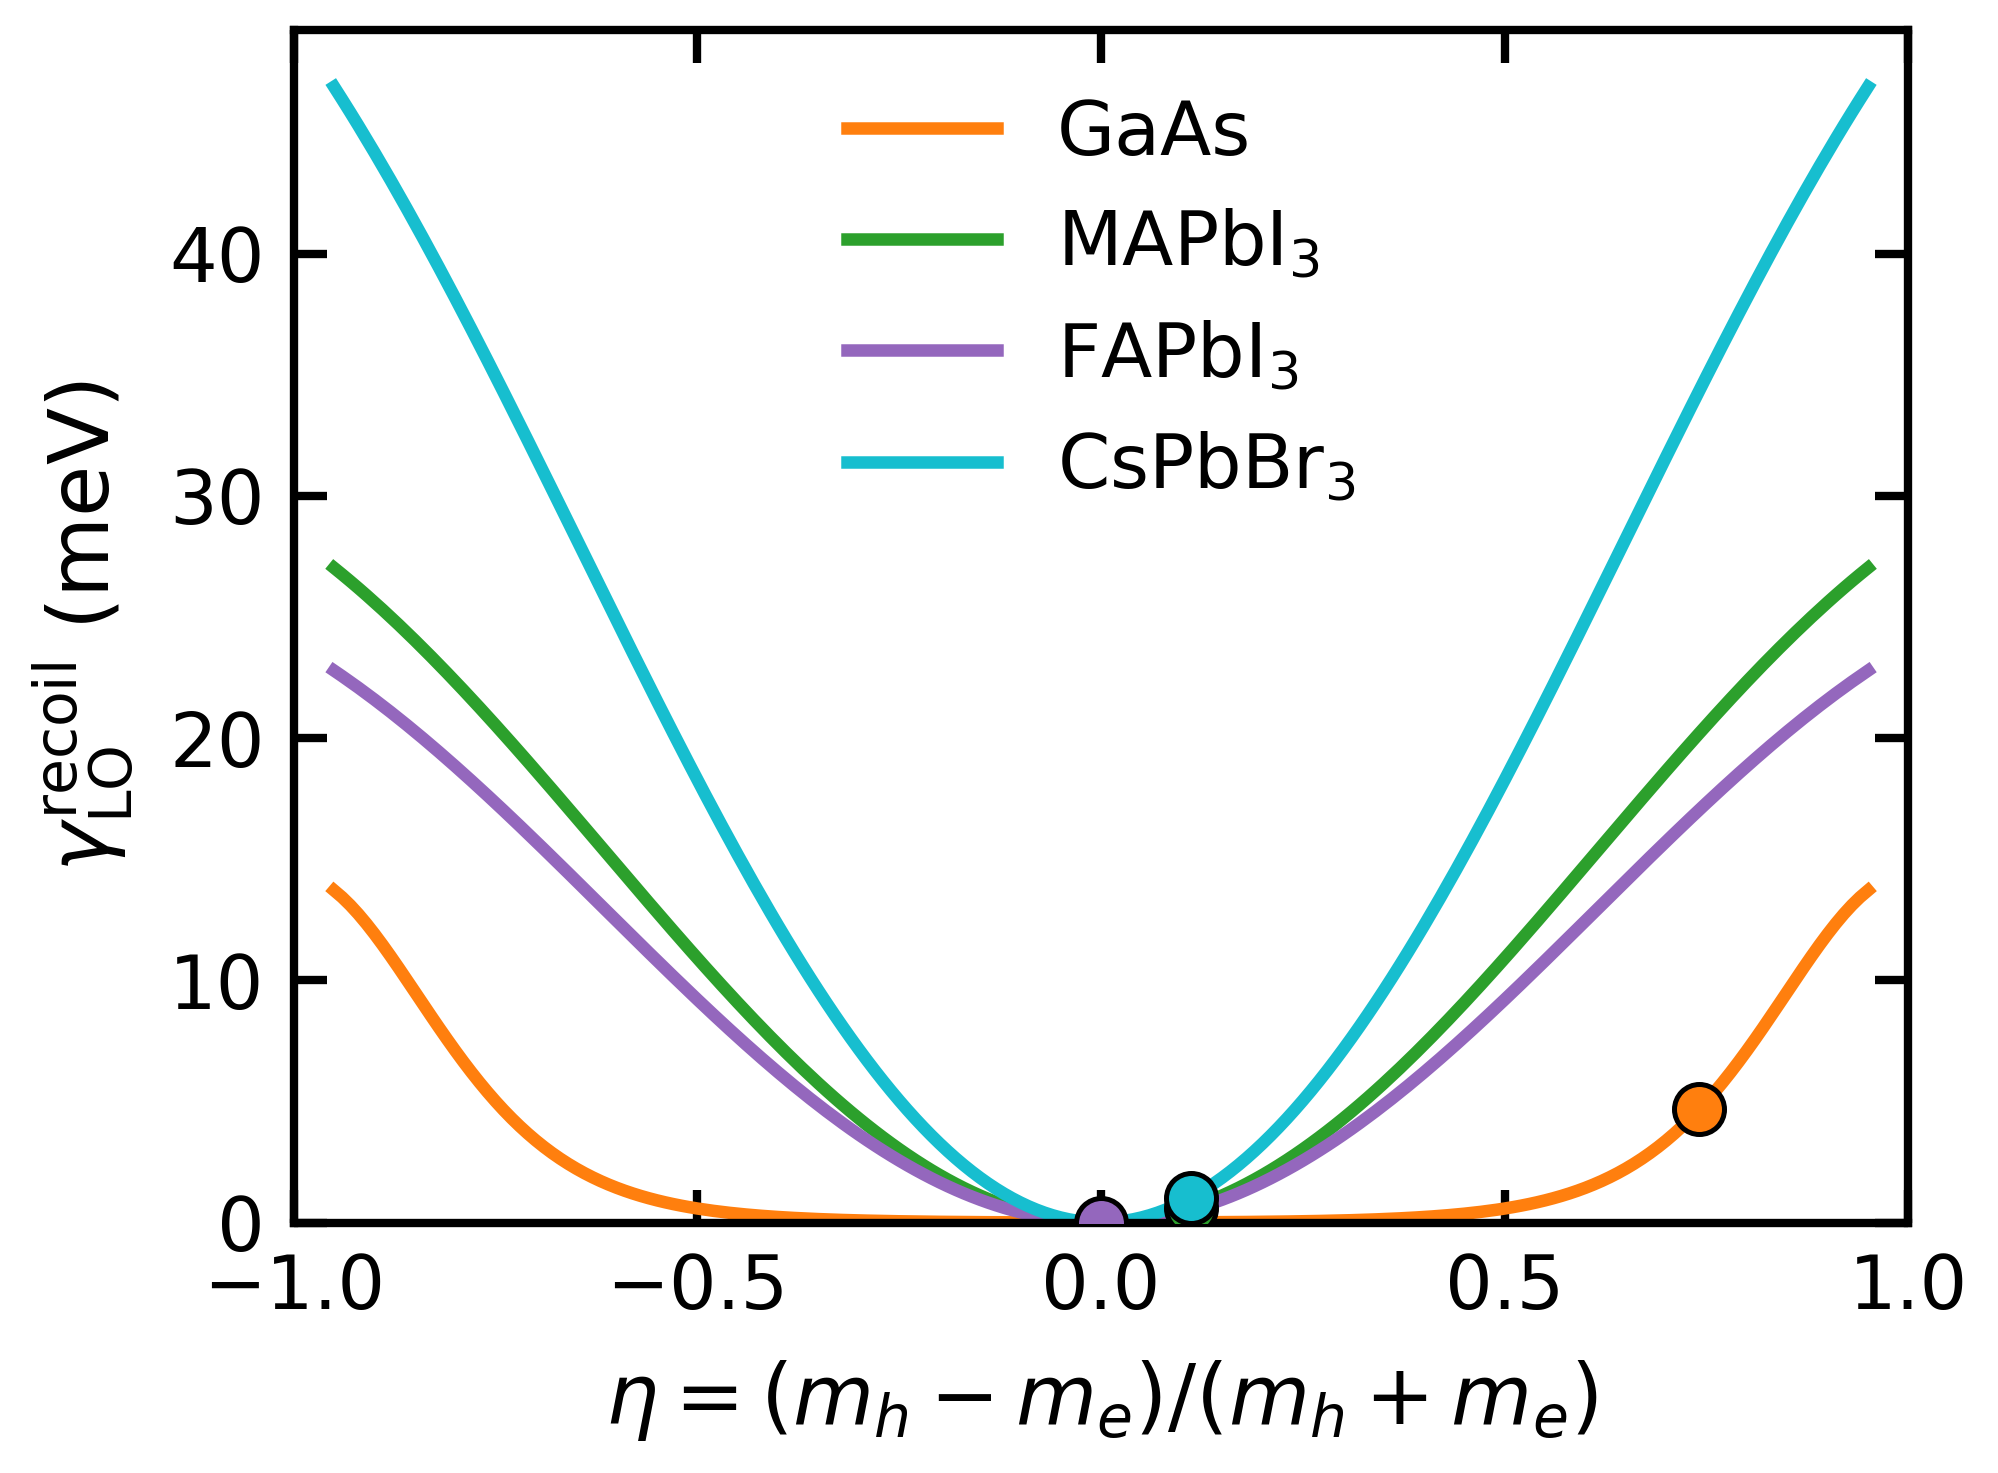

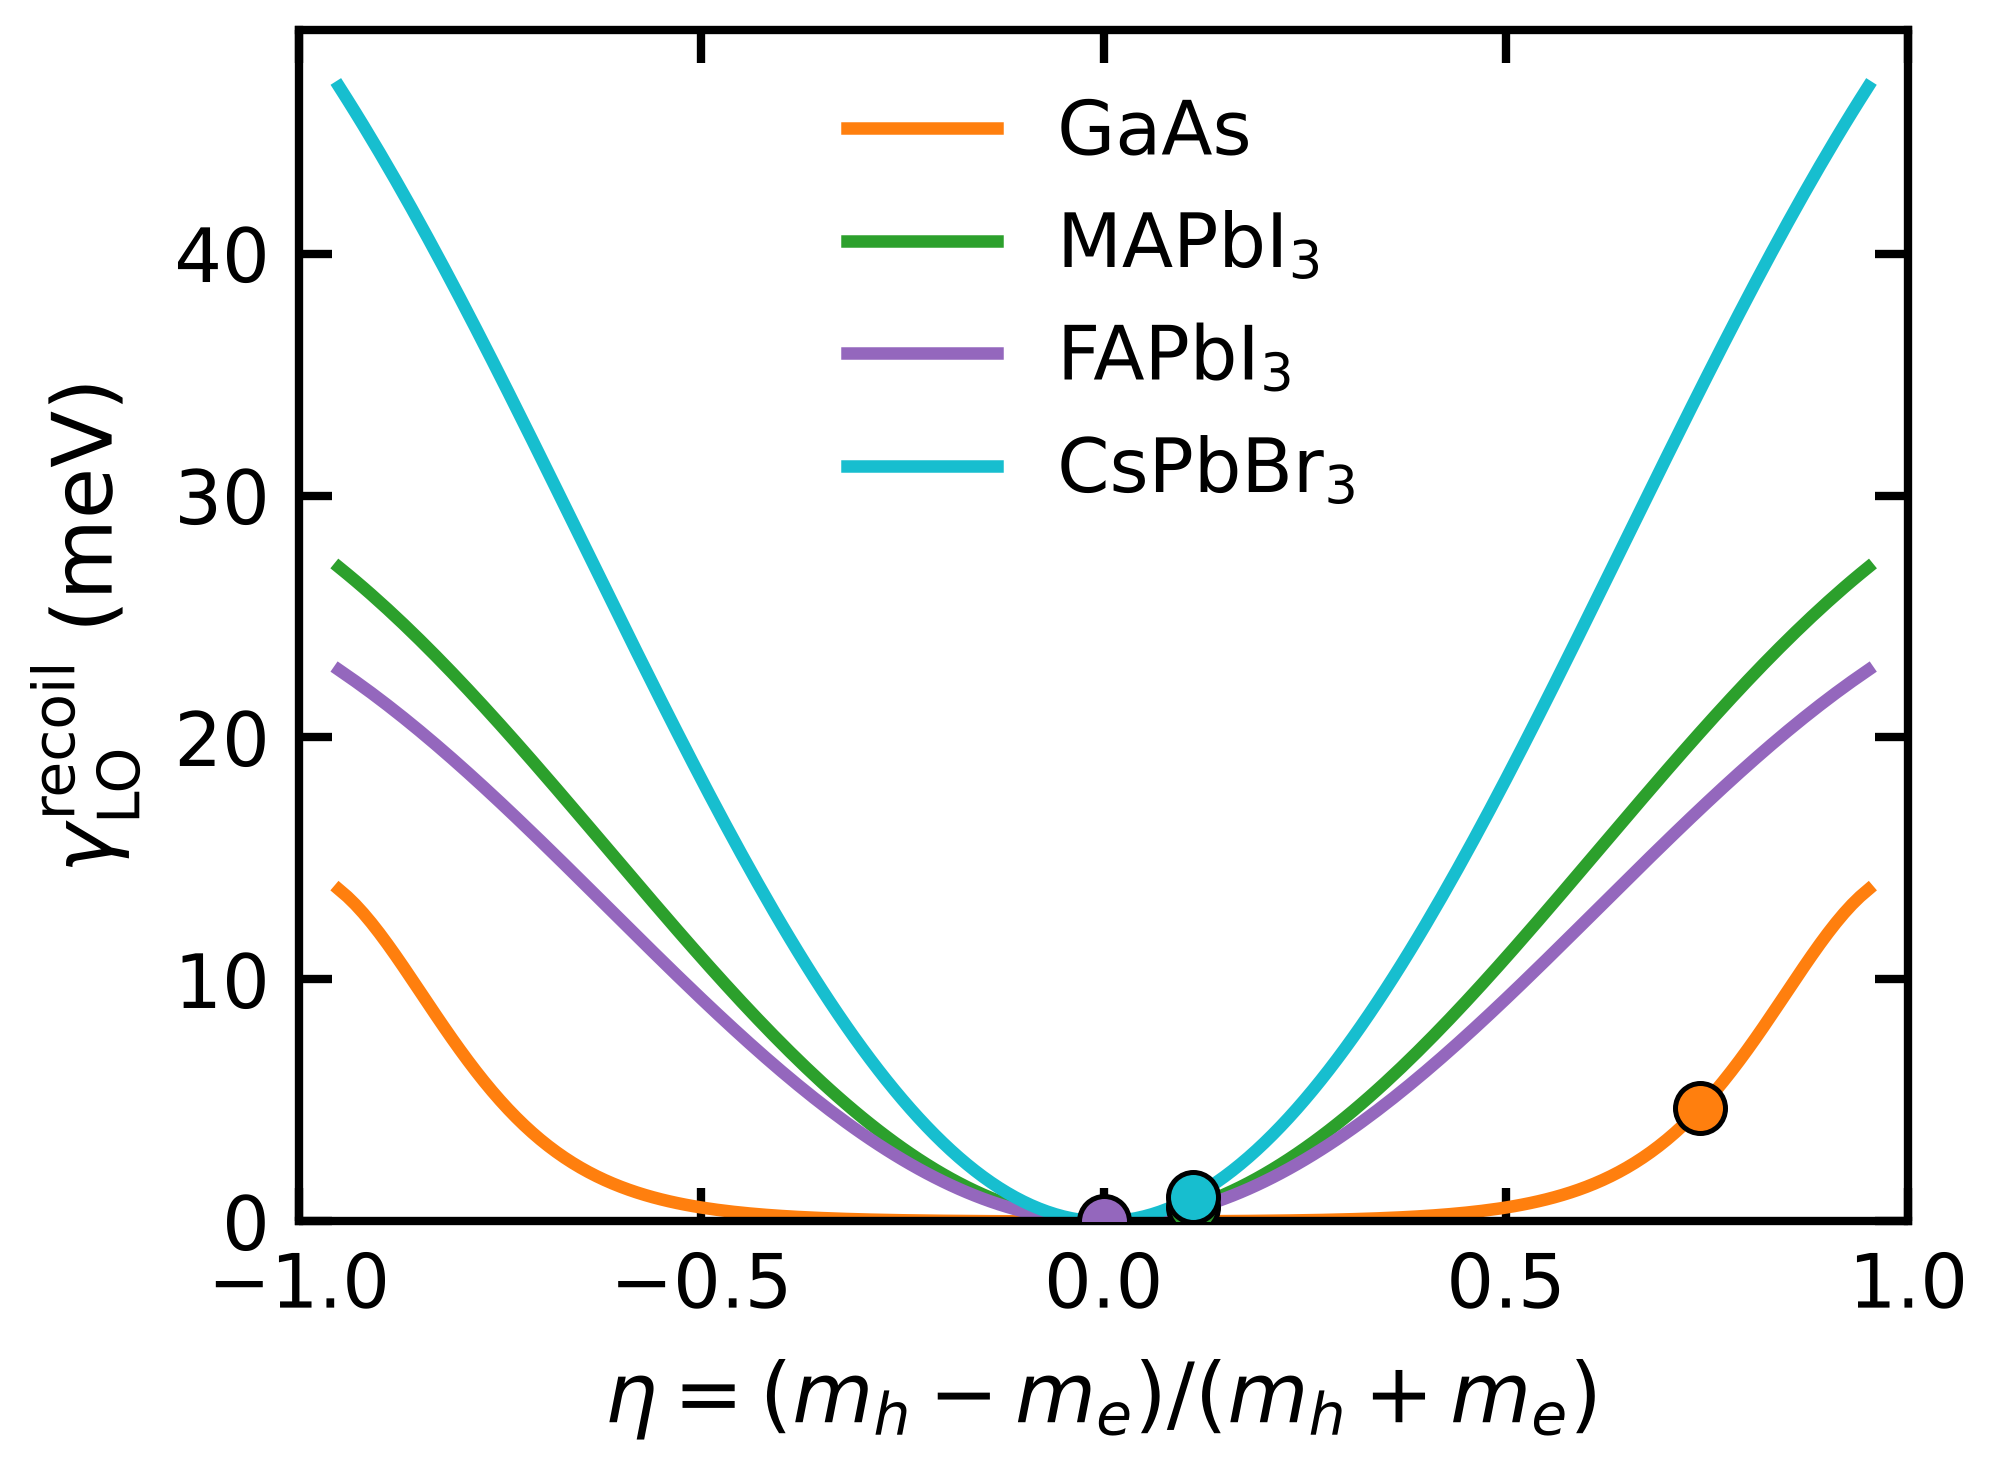

In [16]:
cols = {"GaAs": "#ff7f0e", "MAPbI3": "#2ca02c", "FAPbI3": "#9467bd", "CsPbBr3": "#17becf"}
labs = {"GaAs": "GaAs", "MAPbI3": r"MAPbI$_3$", "FAPbI3": r"FAPbI$_3$", "CsPbBr3": r"CsPbBr$_3$"}
eta_scan = np.linspace(-0.95, 0.95, 191)
fig, ax = highquality_figure(width='single')
for k, p in MATS.items():
    Mt = p["me"] + p["mh"]
    gs = [recoil(Mt/2*(1 - et), Mt/2*(1 + et), p["hw"], aX_nm(p), inv_eps(p))[0] for et in eta_scan]
    ax.plot(eta_scan, gs, color=cols[k], lw=1.5, label=labs[k])
    g0 = recoil(p["me"], p["mh"], p["hw"], aX_nm(p), inv_eps(p))[0]
    ax.plot(eta_of(p), g0, 'o', color=cols[k], ms=6, mec='k', mew=0.6, zorder=5)
ax.set_xlabel(r'$\eta=(m_h-m_e)/(m_h+m_e)$'); ax.set_ylabel(r'$\gamma_{\rm LO}^{\rm recoil}$ (meV)')
ax.set_xlim(-1, 1); ax.set_ylim(bottom=0); ax.legend(loc='upper center')
plt.tight_layout()
highquality_save(fig, 'figure5_recoil_vs_eta.pdf'); highquality_save(fig, 'figure5_recoil_vs_eta.png')
plt.show()

## Figure 6: recoil linewidths versus temperature and comparison with experiment

Saved: figure6_recoil_linewidths.pdf (7.0" x 2.7")
Saved: figure6_recoil_linewidths.png (7.0" x 2.7")


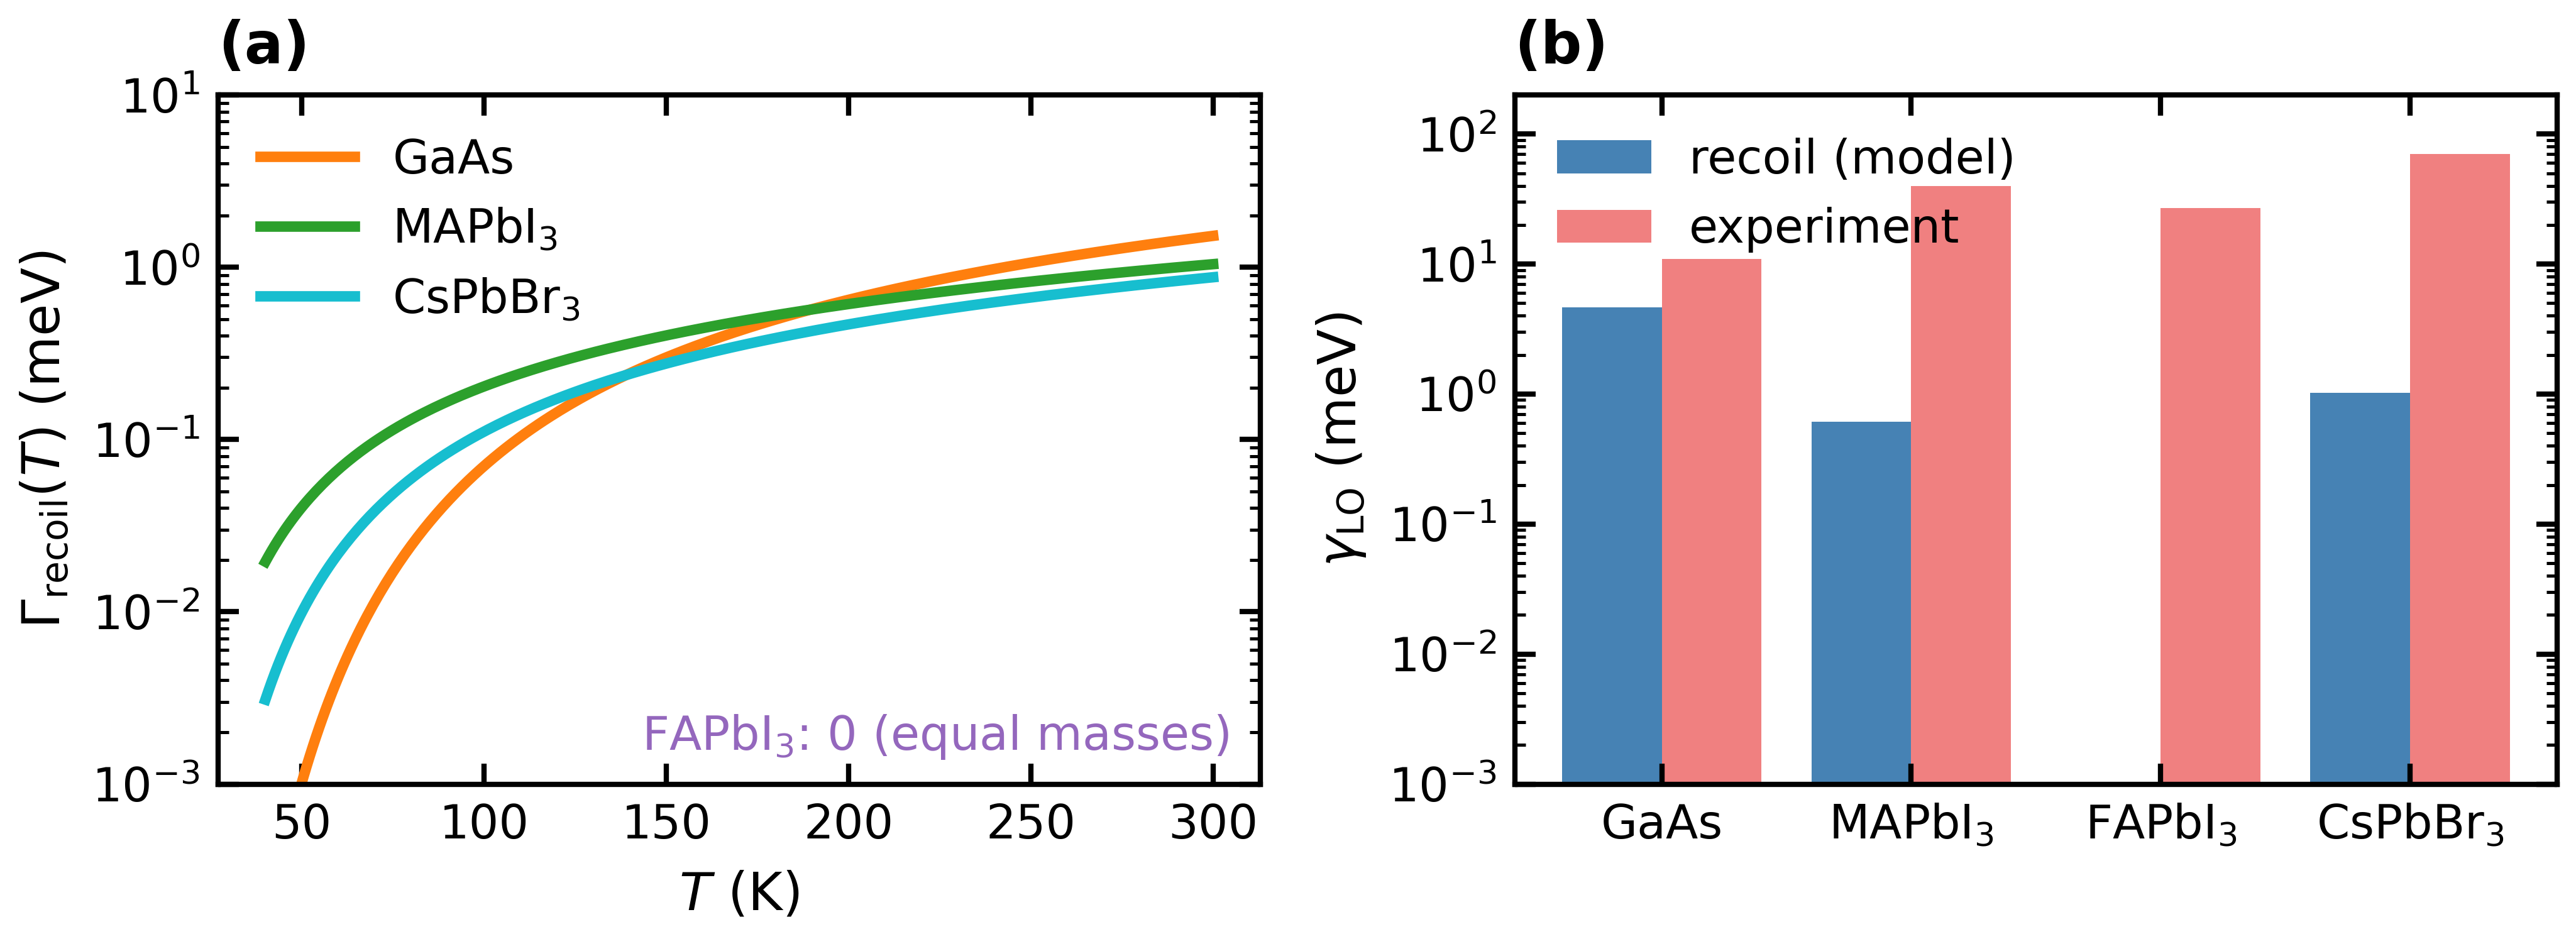

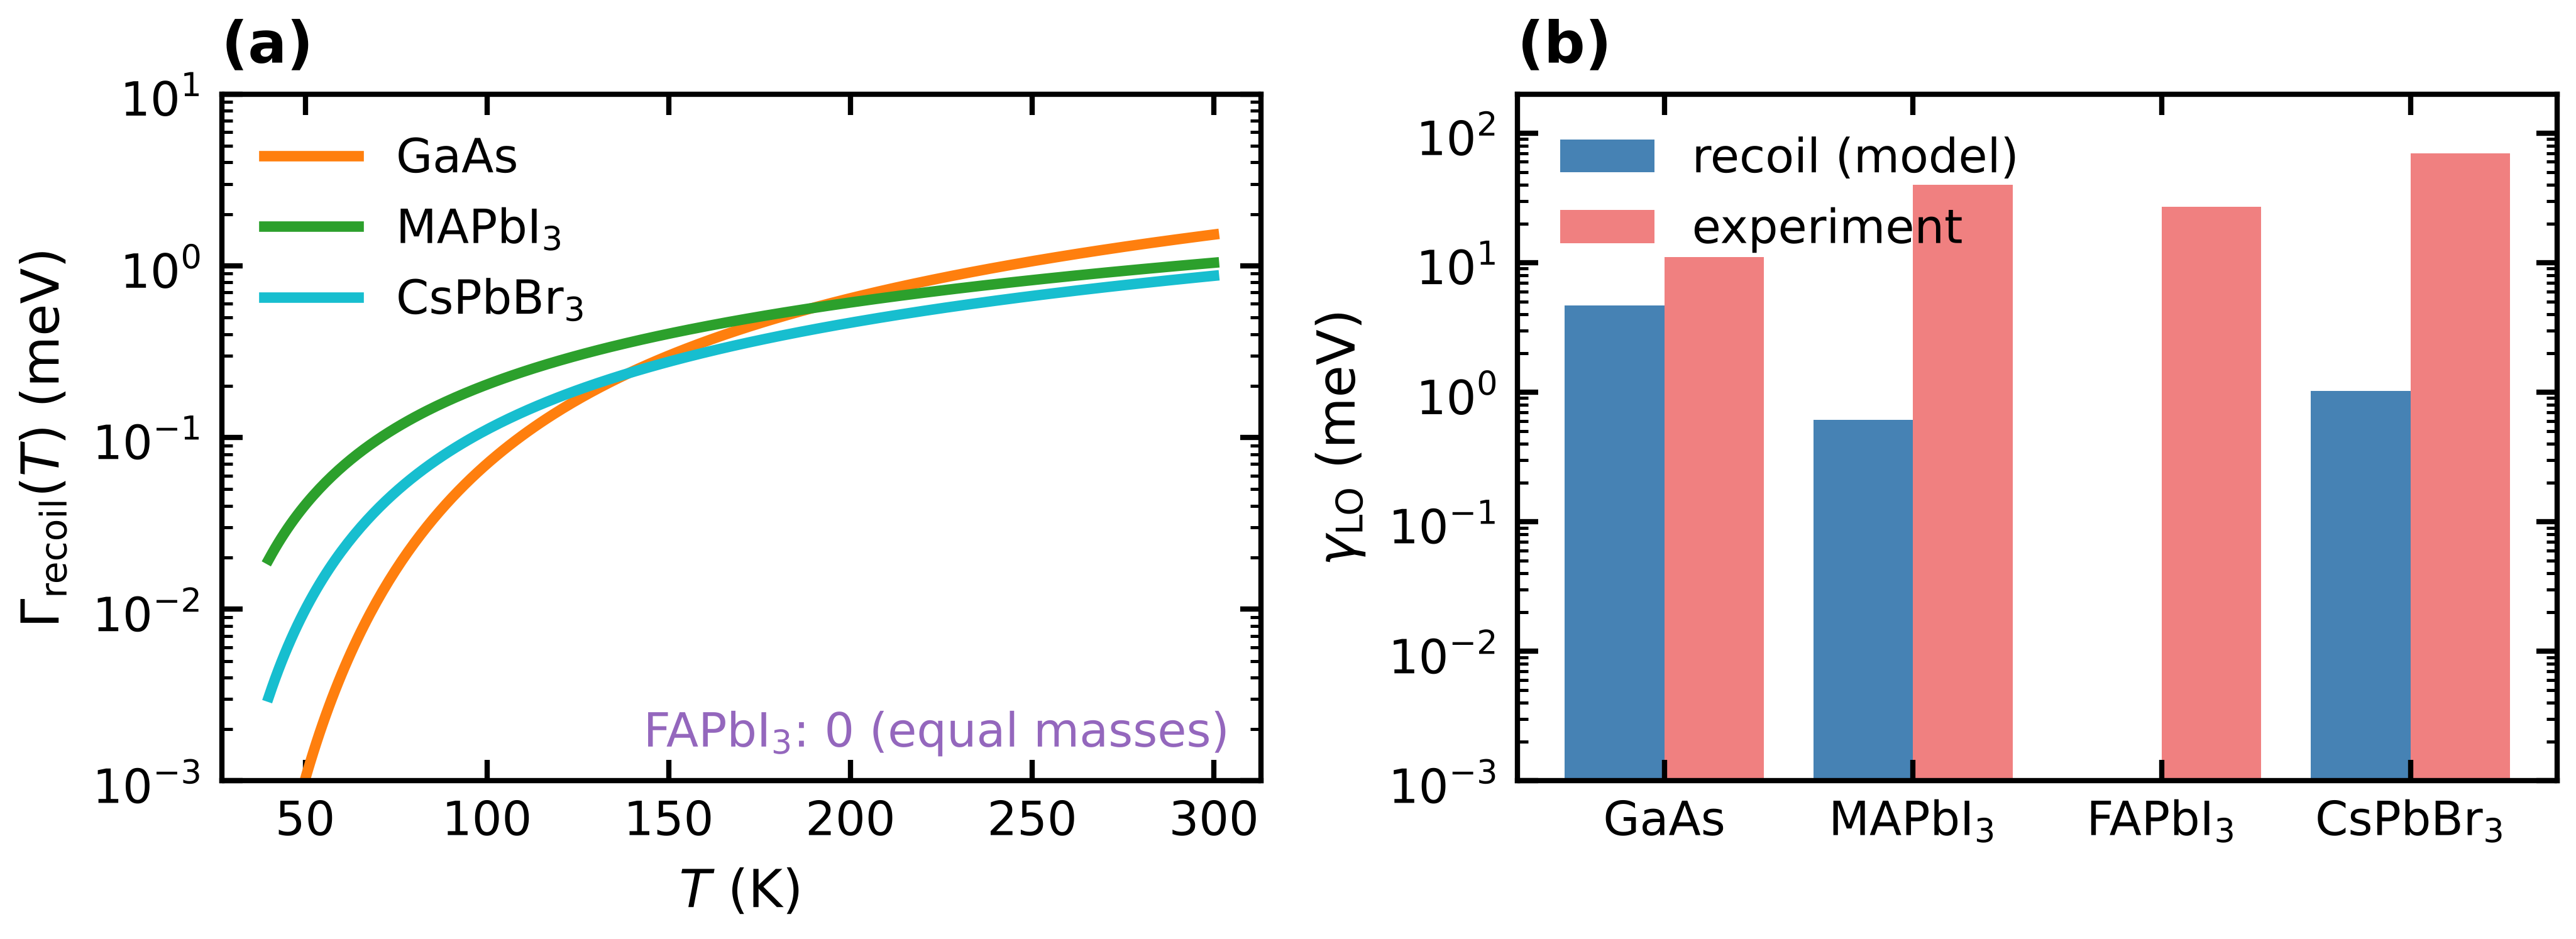

In [17]:
Ts = np.linspace(40, 300, 300)
fig, axs = highquality_figure(width='double', height_ratio=0.38, nrows=1, ncols=2)
g_rec = {}
for k, p in MATS.items():
    g_rec[k] = recoil(p["me"], p["mh"], p["hw"], aX_nm(p), inv_eps(p))[0]
    if g_rec[k] > 1e-12:
        N = 1/np.expm1(p["hw"]/(kB_meV*Ts))
        axs[0].semilogy(Ts, g_rec[k]*N, color=cols[k], label=labs[k])
axs[0].text(0.97, 0.05, r'FAPbI$_3$: 0 (equal masses)', transform=axs[0].transAxes,
            ha='right', color=cols["FAPbI3"])
axs[0].set_xlabel(r'$T$ (K)'); axs[0].set_ylabel(r'$\Gamma_{\rm recoil}(T)$ (meV)')
axs[0].set_ylim(1e-3, 10); axs[0].legend(loc='upper left'); axs[0].set_title('(a)', loc='left')

xs = np.arange(len(MATS)); names = list(MATS)
axs[1].bar(xs - 0.2, [max(g_rec[k], 1e-3) for k in names], 0.4, color='steelblue', label='recoil (model)')
axs[1].bar(xs + 0.2, [EXP_MID[k] for k in names], 0.4, color='lightcoral', label='experiment')
axs[1].set_yscale('log'); axs[1].set_ylim(1e-3, 2e2)
axs[1].set_xticks(xs); axs[1].set_xticklabels([labs[k] for k in names])
axs[1].set_ylabel(r'$\gamma_{\rm LO}$ (meV)'); axs[1].legend(loc='upper left'); axs[1].set_title('(b)', loc='left')
plt.tight_layout()
highquality_save(fig, 'figure6_recoil_linewidths.pdf'); highquality_save(fig, 'figure6_recoil_linewidths.png')
plt.show()